# Workshop 4 · Estadística para IA
Estacionariedad, regresión espuria, cointegración y modelos ARIMA/SARIMA

A01199004 Oswaldo Hernández


In [ ]:
# Paquete del INEGI que se usa en la Parte C (Colab no lo trae instalado).
# Si se reinicia el entorno de ejecución hay que volver a correr esta celda.
!pip install -q INEGIpy==2.0.0

# Stationary vs Non-Stationary series

Distinción entre series Estacionarias y series No estacionarias.

En resumen:

Una serie Estacionaria:
- Tiene un promedio estable a través del timepo; en otras palabras, la serie casi siempre tiende a su promedio histórico.
- La desviación estándar de la serie a través del tiempo es estable (que la varianza es "homogénea") y quiere decir que en cualquier ventana de tiempo si calculo la desviación estándar va a ser parecida entre estas ventanas.

Ejemplos de series estacionarias:
- Frecuencia cardiaca: El número de latidos del corazón por minuto en reposo. (promedio 70 y desv estándar 20)
- Retornos de una acción: Es estacionaria porque tiene un promedio cercano a 0 pero no es tan homogénea en volatilidad.

Una serie no estacionaria:
- Su promedio no es estable, cambia significativamente dependiendo de la ventana de tiempo.
- Su desviación estándar no es homogénea.

Ejemplos de series no estacionarias:
- Series crecientes a largo plazo. (precio de las casas, precios de acciones de empresas)
- Series decrecientes a largo plazo. (precios de acciones que quiebran en el mercado financiero, precio de mercado de autos usados)
- Series no predecibles, a veces suben por un tiempo, luego bajan y no siguen un patrón.

Observaciones:
La serie de random walk es una serie no estacionaria. Qué tipo de no-estacionaria es?

Depende del drift (phi0), entonces va a ser una serie no predecible sin tendencia clara. Si phi0 > 0 y no es tan pequeña vs su desv estándar entonces será una serie Creciente, pero si phi0 < 0 y no es tan pequeña vs su desv estándar, entonces será una serie Decreciente.

Podemos modelar una serie estacionaria con un:

$$phi1 < 1$$

[*********************100%***********************]  1 of 1 completed


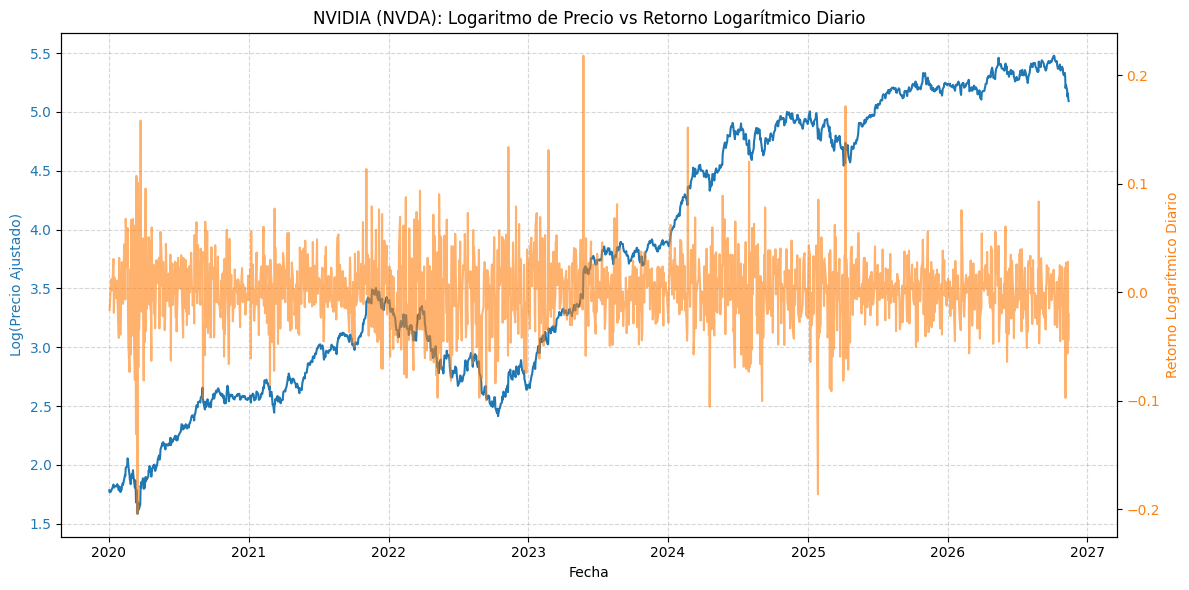

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Descargar datos de NVIDIA (NVDA) desde enero de 2020 con auto_adjust=True
ticker = 'NVDA'
df = yf.download(ticker, start='2020-01-01', auto_adjust=True)

# Manejar columnas en caso de que yfinance devuelva un MultiIndex
if isinstance(df.columns, pd.MultiIndex):
    # Nos quedamos con el nivel de precio y removemos el nivel de Ticker si existe
    df.columns = df.columns.get_level_values(0)

# El precio ajustado estará en la columna 'Close' debido a auto_adjust=True
# Creamos una serie limpia para trabajar
prices = df['Close'].dropna()

# Calcular el logaritmo del precio
log_price = np.log(prices)

# Calcular el retorno logarítmico diario
log_return = log_price.diff()

# Crear el gráfico con doble eje Y
fig, ax1 = plt.subplots(figsize=(12, 6))

# Primer eje Y: Logaritmo del precio
color = 'tab:blue'
ax1.set_xlabel('Fecha')
ax1.set_ylabel('Log(Precio Ajustado)', color=color)
ax1.plot(prices.index, log_price, color=color, label='Log Precio')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.5)

# Segundo eje Y: Retornos logarítmicos
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Retorno Logarítmico Diario', color=color)
ax2.plot(prices.index, log_return, color=color, alpha=0.6, label='Retorno Logarítmico')
ax2.tick_params(axis='y', labelcolor=color)

# Título y mostrar gráfico
plt.title('NVIDIA (NVDA): Logaritmo de Precio vs Retorno Logarítmico Diario')
fig.tight_layout()
plt.show()

La regresión espuria es la que es falsa, los estadísticos como p-value, t-value salen significativos por lo tanto no podemos contemplarlos como válidos, pero hay una forma de saber cuándo es válido, las dos series tienen que ser estacionarias aplicando los dos pasos, sacando el logaritmo y el porcentaje de cambio (como el ejemplo anterior).

Si las dos series están co-integradas (co-integración) es como una especie de correlación pero esta se aplica a variables no estacionarias y de manera general mide qué tanto están conectadas a largo plazo.

# Parte A. Estacionariedad

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from io import BytesIO, StringIO
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.graphics.tsaplots import plot_acf

# Algunos servidores rechazan descargas que no parecen venir de un navegador;
# este encabezado hace que la petición parezca venir de Chrome
headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0 Safari/537.36'}

## Del random walk al modelo AR(1)

En el Workshop 3 modelamos el logaritmo del S&P 500 como una caminata aleatoria con drift, donde el valor de hoy es el de ayer más una constante phi0 más un choque y el problema es que la serie nunca regresa a ningún nivel ya que cada choque se queda para siempre por lo que la incertidumbre crece con el tiempo (la desviación estándar crece con la raíz de t).

Si en lugar de copiar completo el valor de ayer nos quedamos solo con una fracción phi1 de él tednríamos el modelo autorregresivo de orden 1 o AR(1) donde phi1 es como la memoria de la serie y la caminata aleatoria es el caso especial donde phi1 es igual a 1.

Una serie es estacionaria cuando su media es la misma en todos los periodos, su varianza también es la misma y la covarianza entre el valor de hoy y el de k periodos atrás solo depende de la distancia k y no del momento en el que estemos o sea que si cortamos la serie en pedazos cada pedazo se ve estadísticamente parecido.

Si el AR(1) es estacionario su media es la misma hoy que ayer por lo que al sacar el valor esperado de la ecuación queda que la media de largo plazo es phi0 entre uno menos phi1 y la varianza es la varianza del choque entre uno menos phi1 al cuadrado la cual solo es positiva y finita cuando el valor absoluto de phi1 es menor que 1.

Por eso cuando el valor absoluto de phi1 es menor que 1 la serie es estacionaria y regresa a su media después de un choque, cuando phi1 es igual a 1 hay raíz unitaria (unit root) y los choques son permanentes y cuando es mayor que 1 la serie explota.

La vida media (half-life) es cuántos periodos tarda en desaparecer la mitad del efecto de un choque y como después de k periodos queda phi1 elevado a la k del choque, se calcula como el logaritmo de 0.5 entre el logaritmo del valor absoluto de phi1.

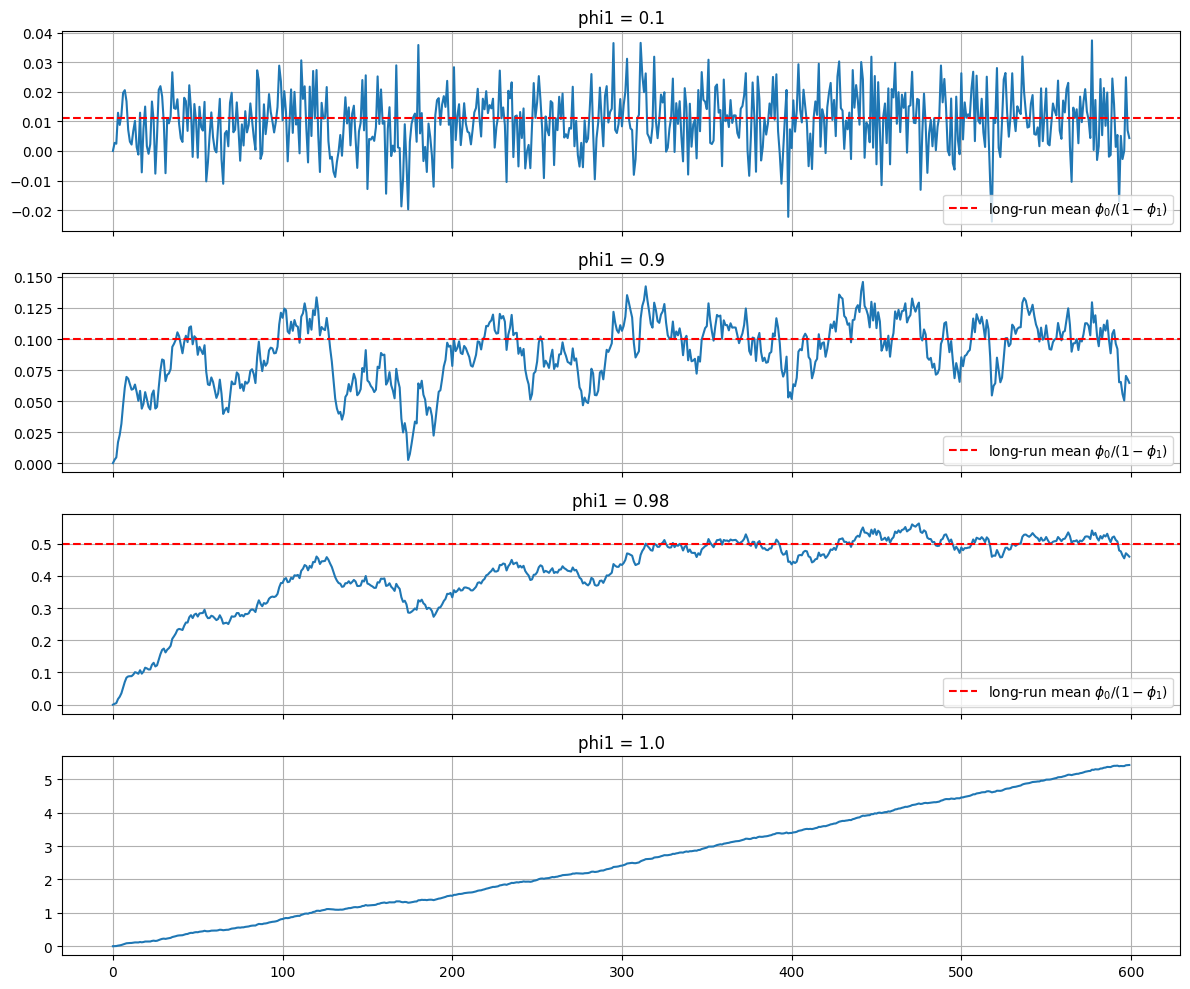

In [ ]:
def simulate_ar1(phi0, phi1, shocks, y0=0.0):
    """Simula Y_t = phi0 + phi1*Y_{t-1} + e_t usando los choques (shocks) dados."""
    y = np.zeros(len(shocks))
    y[0] = y0
    for t in range(1, len(shocks)):
        y[t] = phi0 + phi1 * y[t-1] + shocks[t]
    return y

n = 600
rng = np.random.default_rng(10)
shocks = rng.normal(0, 0.01, n)           # sigma del choque = 0.01
phi0 = 0.01
phi1_values = [0.10, 0.90, 0.98, 1.00]

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
sims = {}
for ax, p1 in zip(axes, phi1_values):
    sims[p1] = simulate_ar1(phi0, p1, shocks)   # simula con los MISMOS choques
    ax.plot(sims[p1])
    if p1 < 1:                            # la media de largo plazo solo existe si phi1 < 1
        ax.axhline(phi0 / (1 - p1), color='red', linestyle='--', label=r'long-run mean $\phi_0/(1-\phi_1)$')
        ax.legend(loc='lower right')
    ax.set_title(f'phi1 = {p1}')
    ax.grid(True)
plt.tight_layout()
plt.show()

En esta parte simulamos cuatro series AR(1) con la función simulate_ar1, la cual va construyendo la serie paso a paso sumando phi0 + phi1 por el valor de ayer + un choque aleatorio.

A las cuatro simulaciones les pasamos exactamente los mismos choques, por lo que lo único que cambia entre ellas es phi1, es decir que cualquier diferencia que se vea en las gráficas viene de qué tanto recuerda la serie lo que pasó antes.

La línea roja punteada es la media de largo plazo que se calcula como phi0 entre uno menos phi1 y solo existe cuando phi1 es menor que 1 ya que con phi1 igual a 1 la división sería entre cero, por eso en la última gráfica no aparece y la serie solo va subiendo por el drift.

In [ ]:
rows = []
for p1 in phi1_values:
    y = sims[p1][n // 2:]                  # solo la segunda mitad, para que y0 = 0 no distorsione
    rows.append({
        'phi1': p1,
        'theoretical mean': phi0 / (1 - p1) if p1 < 1 else np.nan,
        'sample mean (2nd half)': y.mean(),
        'lag-1 autocorrelation': pd.Series(y).autocorr(1),
        'half-life (periods)': np.log(0.5) / np.log(p1) if p1 < 1 else np.inf,
    })
ar1_table = pd.DataFrame(rows).round(4)
ar1_table

,phi1,theoretical mean,sample mean (2nd half),lag-1 autocorrelation,half-life (periods)
0,0.10,0.0111,0.0112,0.0202,0.3010
1,0.90,0.1000,0.1020,0.8303,6.5788
2,0.98,0.5000,0.4994,0.9217,34.3096
3,1.00,NaN,3.9554,0.9999,inf


Para comparar la teoría con la simulación usamos solo la segunda mitad de cada serie ya que la serie empieza en cero y tarda un tiempo en llegar a su media, por lo que si usáramos toda la serie la media saldría distorsionada.

Con phi1 de 0.10, 0.90 y 0.98 la media muestral quedó muy cerca de la teórica, mientras que con phi1 igual a 1 la media muestral no significa nada porque la serie nunca se estabiliza.

La vida media es cuántos periodos tarda en desaparecer la mitad de un choque, por lo que entre más cerca esté phi1 de 1 más tarda la serie en olvidar un choque hasta que con phi1 igual a 1 la vida media es infinita.

Preguntas de clase sobre la simulación AR(1):

1. ¿Qué le pasa a la serie cuando phi1 es pequeño (0.10) y cuando está cerca de 1? Cuando phi1 es pequeño la serie parece ruido y regresa a su media casi de inmediato, en cambio cuando phi1 está cerca de 1 la serie se queda lejos de su media mucho tiempo antes de regresar.
2. Con phi1 de 0.98, ¿cuántos periodos tarda en desaparecer la mitad de un choque y qué implica para un pronóstico a 12 periodos? Con phi1 de 0.98 la vida media es de unos 34 periodos, o sea que después de 12 periodos todavía queda alrededor del 78% del choque (0.98 elevado a la 12), por lo que un pronóstico a 12 periodos todavía estaría lejos de la media de largo plazo.
3. ¿Por qué a una prueba estadística le cuesta distinguir una serie con phi1 de 0.98 de una caminata aleatoria? En ventanas cortas una serie con phi1 de 0.98 y una caminata aleatoria se ven casi iguales, ya que en pocos datos la de 0.98 casi no alcanza a regresar a su media, por lo que a una prueba estadística le cuesta mucho trabajo distinguirlas.

## Autocorrelación

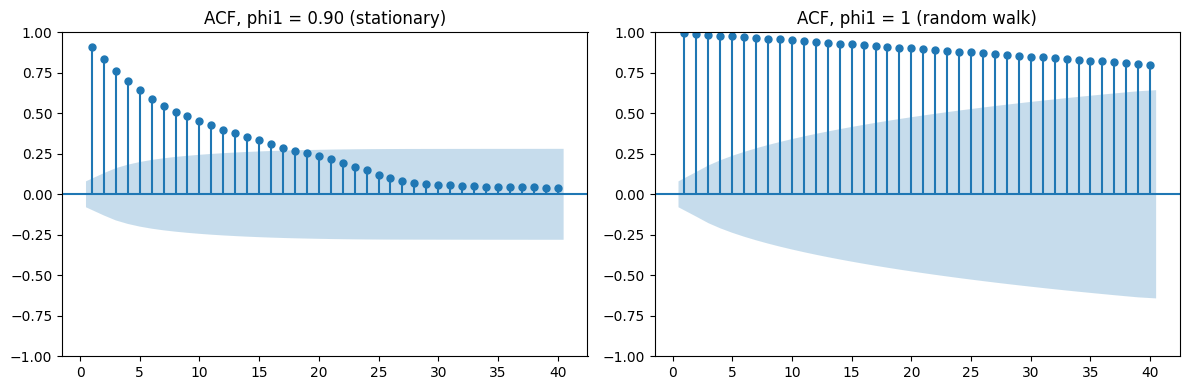

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# zero=False quita el rezago 0, que siempre vale 1 y no aporta información
plot_acf(sims[0.90], lags=40, zero=False, ax=axes[0], title='ACF, phi1 = 0.90 (stationary)')
plot_acf(sims[1.00], lags=40, zero=False, ax=axes[1], title='ACF, phi1 = 1 (random walk)')
plt.tight_layout()
plt.show()

La autocorrelación en el rezago k es la correlación de la serie con ella misma k periodos atrás y la ACF la grafica para muchos rezagos donde la zona azul es la banda de confianza del 95%, es decir que las barras que se salen de ella son significativas.

Para un AR(1) estacionario la teoría dice que la autocorrelación es phi1 elevado a la k, por lo que en la serie con phi1 de 0.90 las barras van bajando rápido y después de unos cuantos rezagos ya entran en la zona azul mientras que en la caminata aleatoria las barras bajan muy despacio y siguen fuera de la banda incluso en el rezago 40 lo cual es una señal visual de que la serie tiene raíz unitaria.

## Datos reales: ventas de productos de consumo

In [ ]:
url = "http://www.apradie.com/ec2004/salesbrands3.xlsx"
response = requests.get(url, headers=headers)
response.raise_for_status()
sales_brand = pd.read_excel(BytesIO(response.content), sheet_name='Resultado')

In [ ]:
sales_brand['date'] = pd.to_datetime(sales_brand['date'])
sales_brand = sales_brand.set_index('date').sort_index().asfreq('MS')    # MS = frecuencia mensual, inicio de mes
brand_cols = [c for c in sales_brand.columns if c.startswith('qbrand')]
print(brand_cols)

['qbrand1tons', 'qbrand2tons', 'qbrand3tons', 'qbrand4tons', 'qbrand5tons', 'qbrand6tons']


Aquí descargamos la base de ventas mensuales en volumen (toneladas) de seis marcas de una misma categoría de productos de consumo.

Convertimos la columna de fecha a tipo fecha, la pusimos como índice y con asfreq('MS') le decimos a pandas que la serie es mensual y que cada fecha es el primer día del mes ya que las funciones de series de tiempo necesitan saber la frecuencia.

Al final guardamos en brand_cols los nombres de las columnas de las seis marcas para poder recorrerlas con un ciclo más adelante.

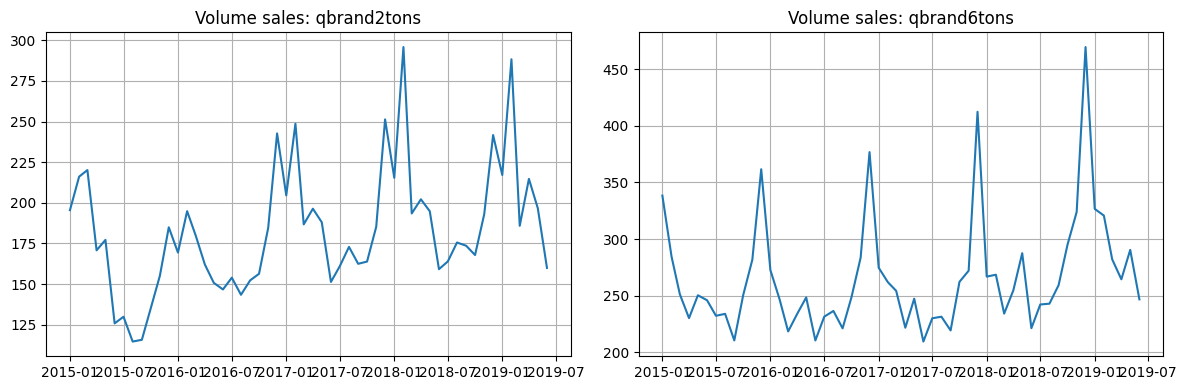

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['qbrand2tons', 'qbrand6tons']):
    ax.plot(sales_brand.index, sales_brand[col])
    ax.set_title(f'Volume sales: {col}')
    ax.grid(True)
plt.tight_layout()
plt.show()

Las ventas de las marcas 2 y 6 tienen tendencia y además un patrón que se repite cada año (estacionalidad) por lo que su media cambia dependiendo del periodo que veamos o dicho de otra forma que no son estacionarias y así se comportan la mayoría de las variables de negocio como las ventas, los ingresos, los costos o los precios.

## Transformaciones: logaritmo y diferencias

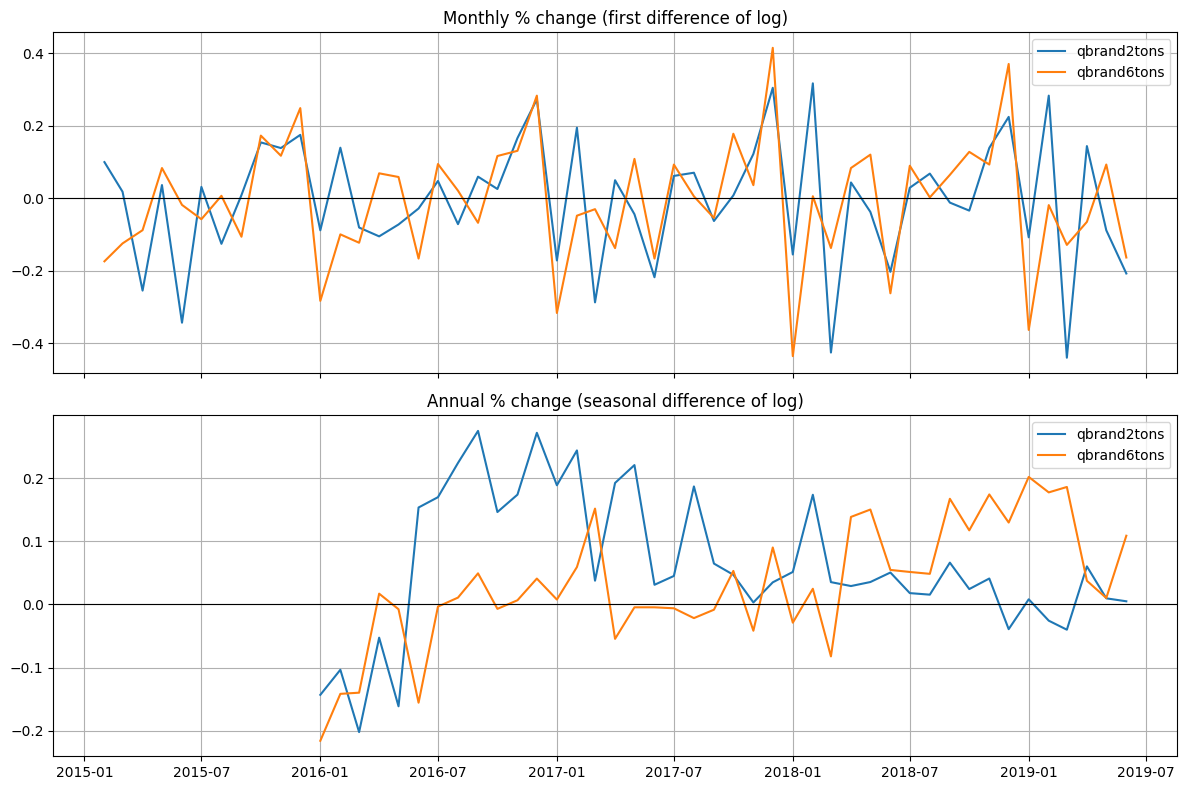

In [ ]:
ln_sales = np.log(sales_brand[brand_cols])
msales_growth = ln_sales.diff(1)             # cambio % mensual
ysales_growth = ln_sales.diff(12)            # cambio % anual

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for col in ['qbrand2tons', 'qbrand6tons']:
    axes[0].plot(msales_growth.index, msales_growth[col], label=col)
    axes[1].plot(ysales_growth.index, ysales_growth[col], label=col)
axes[0].set_title('Monthly % change (first difference of log)')
axes[1].set_title('Annual % change (seasonal difference of log)')
for ax in axes:
    ax.axhline(0, color='black', linewidth=0.8)
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.show()

Para volver estacionaria una serie de negocio primero sacamos el logaritmo, ya que convierte los cambios proporcionales en sumas y estabiliza la varianza cuando esta crece con el nivel, después sacamos la diferencia del logaritmo que es el cambio porcentual.

Esto funciona porque el logaritmo de hoy menos el de ayer es el logaritmo de hoy entre ayer que es aproximadamente el cambio porcentual cuando el cambio es pequeño, pero cuando el cambio es grande hay que regresar al cambio simple con la exponencial de la diferencia menos uno, por ejemplo una diferencia de -0.25 en realidad es una caída de 22.1% y no de 25%.

Con datos mensuales usamos dos diferencias, la primera diferencia con diff(1) que es el cambio porcentual mensual y la diferencia estacional con diff(12) que compara cada mes con el mismo mes del año pasado, es decir el cambio porcentual anual.

En la gráfica se ve que el cambio mensual ya no tiene tendencia pero todavía tiene picos que se repiten cada año, mientras que el cambio anual ya no tiene ni tendencia ni estacionalidad aunque a simple vista no se puede decidir si ya es estacionaria por eso necesitamos una prueba estadística.

## La prueba de Dickey-Fuller Aumentada (ADF)

In [ ]:
from statsmodels.tsa.stattools import adfuller, kpss

def adf_test(x, regression='c'):
    """Corre la prueba ADF y regresa los resultados clave en un diccionario."""
    res = adfuller(x.dropna(), regression=regression, autolag='AIC')
    # res[0] = estadístico, res[1] = p-value, res[2] = rezagos usados, res[3] = observaciones usadas
    return {'ADF stat': res[0], 'p-value': res[1], 'lags used': res[2], 'obs': res[3]}

q2 = 'qbrand2tons'
adf_q2 = pd.DataFrame({
    'log level (ct)': adf_test(ln_sales[q2], 'ct'),
    'monthly % change (c)': adf_test(msales_growth[q2], 'c'),
    'annual % change (c)': adf_test(ysales_growth[q2], 'c'),
}).T.round(4)
adf_q2

/tmp/ipykernel_502/2128191227.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(x.dropna(), regression=regression, autolag='AIC')
/tmp/ipykernel_502/2128191227.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(x.dropna(), regression=regression, autolag='AIC')
/tmp/ipykernel_502/2128191227.py:5: FutureWarning: adfuller currently returns a 

,ADF stat,p-value,lags used,obs
log level (ct),-0.3013,0.9895,11.0,42.0
monthly % change (c),-2.7994,0.0584,11.0,41.0
annual % change (c),-2.4884,0.1183,3.0,38.0


In [ ]:
p_level = adf_q2.loc['log level (ct)', 'p-value']
p_annual = adf_q2.loc['annual % change (c)', 'p-value']
verdict_level = "reject" if p_level < 0.05 else "cannot reject"
verdict_annual = "reject" if p_annual < 0.05 else "cannot reject"
print(f"Log level: p = {p_level:.4f} -> {verdict_level} unit root")
print(f"Annual % change: p = {p_annual:.4f} -> {verdict_annual} unit root")

Log level: p = 0.9895 -> cannot reject unit root
Annual % change: p = 0.1183 -> cannot reject unit root


La prueba de Dickey-Fuller aumentada (ADF) parte del AR(1) y le resta el valor de ayer a los dos lados y queda que el cambio de la serie depende de gamma por el valor de ayer donde gamma es phi1 menos 1.

La hipótesis nula es que gamma es cero, que phi1 es 1 y la serie tiene raíz unitaria (no es estacionaria) y la hipótesis alternativa es que gamma es negativa que la serie sí es estacionaria, se le llama aumentada porque agrega rezagos del cambio para quitar la autocorrelación de corto plazo y adfuller escoge cuántos con el AIC además bajo la hipótesis nula el estadístico no sigue una distribución t por lo que se usan valores críticos especiales de Dickey-Fuller.

El argumento regression es importante ya que para los niveles en logaritmo que tienen tendencia usamos 'ct' (constante y tendencia) y para los cambios porcentuales usamos 'c' (solo constante).

Para la marca 2 el nivel en logaritmo tuvo un p-value de 0.99, por lo que no rechazamos la raíz unitaria, el cambio mensual tuvo 0.058 que casi rechaza pero no llega a 0.05 y el cambio anual tuvo 0.118 por lo que tampoco rechazamos.

Hay que tener cuidado porque no rechazar no significa que ya demostramos que la serie no es estacionaria ya que con pocas observaciones (aquí solo 38 en el cambio anual) la prueba tiene poco poder y además la estacionalidad que todavía queda en el cambio mensual puede distorsionar la prueba por eso en datos mensuales de negocio conviene más el cambio anual.

## Verificación cruzada: la prueba KPSS

In [ ]:
kpss_stat, kpss_p, _, _ = kpss(ysales_growth[q2].dropna(), regression='c', nlags='auto')
print(f"KPSS for the annual % change of brand 2: stat = {kpss_stat:.3f}, p-value = {kpss_p:.3f}")

KPSS for the annual % change of brand 2: stat = 0.199, p-value = 0.100


/tmp/ipykernel_502/1499342955.py:1: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_stat, kpss_p, _, _ = kpss(ysales_growth[q2].dropna(), regression='c', nlags='auto')
/tmp/ipykernel_502/1499342955.py:1: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_stat, kpss_p, _, _ = kpss(ysales_growth[q2].dropna(), regression='c', nlags='auto')


La prueba KPSS invierte las hipótesis es decir que su hipótesis nula es que la serie sí es estacionaria por lo que usar las dos pruebas juntas da una conclusión más confiable ya que si la ADF rechaza y la KPSS no la serie es estacionaria, si la ADF no rechaza y la KPSS sí la serie no es estacionaria, si las dos rechazan puede haber un cambio estructural o memoria larga y si ninguna rechaza no hay suficientes datos para decidir.

Para el cambio anual de la marca 2 la KPSS dio un p-value de 0.10 por lo que no rechaza que sea estacionaria y la ADF tampoco rechazó la raíz unitaria entonces ninguna de las dos rechaza y caemos en el caso ambiguo.

Algo a tomar en cuenta es que kpss solo reporta p-values entre 0.01 y 0.10 y manda un aviso (InterpolationWarning) cuando el valor real está fuera de ese rango, por lo que el 0.10 que salió en realidad significa 0.10 o más.

# Challenge 1 (Parte A)

In [ ]:
# Cuántos meses hay por marca, si faltan datos o hay ventas en cero o negativas
# (el logaritmo de 0 o de un negativo no existe y rompería las pruebas)
check = pd.DataFrame({
    'months with data': sales_brand[brand_cols].notna().sum(),
    'missing': sales_brand[brand_cols].isna().sum(),
    'zero or negative': (sales_brand[brand_cols] <= 0).sum(),
    'first month': [sales_brand[c].first_valid_index().strftime('%Y-%m') for c in brand_cols],
    'last month': [sales_brand[c].last_valid_index().strftime('%Y-%m') for c in brand_cols],
}, index=brand_cols)
check

,months with data,missing,zero or negative,first month,last month
qbrand1tons,54,0,0,2015-01,2019-06
qbrand2tons,54,0,0,2015-01,2019-06
qbrand3tons,54,0,0,2015-01,2019-06
qbrand4tons,54,0,0,2015-01,2019-06
qbrand5tons,54,0,0,2015-01,2019-06
qbrand6tons,54,0,0,2015-01,2019-06


### 1 y 2. Tabla de p-values ADF y KPSS de todas las marcas

In [ ]:
import warnings

def kpss_pvalue(x, regression='c'):
    """p-value de la KPSS sin imprimir el aviso, y una etiqueta si quedó en el límite de la tabla (0.01 o 0.10)."""
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')                      # oculta el InterpolationWarning
        p = kpss(x.dropna(), regression=regression, nlags='auto')[1]
    bound = '>= 0.10' if p >= 0.1 else ('<= 0.01' if p <= 0.01 else '')
    return p, bound

def joint_verdict(adf_p, kpss_p, alpha=0.05):
    """Combina ADF (H0: raíz unitaria) y KPSS (H0: estacionaria) con la tabla de decisión del workshop."""
    adf_rej, kpss_rej = adf_p < alpha, kpss_p < alpha
    if adf_rej and not kpss_rej:
        return 'estacionaria'
    if not adf_rej and kpss_rej:
        return 'no estacionaria'
    if adf_rej and kpss_rej:
        return 'ambigua (las dos rechazan)'
    return 'ambigua (ninguna rechaza)'

rows = []
for col in brand_cols:
    try:
        adf_lvl = adf_test(ln_sales[col], 'ct')
        adf_m = adf_test(msales_growth[col], 'c')
        adf_y = adf_test(ysales_growth[col], 'c')
        kp, kbound = kpss_pvalue(ysales_growth[col], 'c')
        rows.append({
            'brand': col,
            'ADF p: log level (ct)': adf_lvl['p-value'],
            'ADF p: monthly % (c)': adf_m['p-value'],
            'ADF p: annual % (c)': adf_y['p-value'],
            'KPSS p: annual % (c)': kp,
            'KPSS limit': kbound,
            'obs used (ADF annual)': adf_y['obs'],
            'annual % verdict (ADF + KPSS)': joint_verdict(adf_y['p-value'], kp),
        })
    except Exception as e:                                    # si una marca falla, se reporta y el ciclo sigue
        print(f"{col}: no se pudo calcular ({type(e).__name__}: {e})")
        rows.append({'brand': col})

ch1 = pd.DataFrame(rows).set_index('brand').round(4)
ch1

/tmp/ipykernel_502/2128191227.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(x.dropna(), regression=regression, autolag='AIC')
/tmp/ipykernel_502/2128191227.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(x.dropna(), regression=regression, autolag='AIC')
/tmp/ipykernel_502/2128191227.py:5: FutureWarning: adfuller currently returns a 

,ADF p: log level (ct),ADF p: monthly % (c),ADF p: annual % (c),KPSS p: annual % (c),KPSS limit,obs used (ADF annual),annual % verdict (ADF + KPSS)
brand,,,,,,,
qbrand1tons,0.9869,0.2227,0.1171,0.0100,<= 0.01,40,no estacionaria
qbrand2tons,0.9895,0.0584,0.1183,0.1000,>= 0.10,38,ambigua (ninguna rechaza)
qbrand3tons,0.9849,0.0074,0.3361,0.1000,>= 0.10,38,ambigua (ninguna rechaza)
qbrand4tons,0.0013,0.0000,0.0000,0.0802,,41,estacionaria
qbrand5tons,0.9758,0.8798,0.0213,0.1000,>= 0.10,33,estacionaria
qbrand6tons,0.8946,0.0258,0.0321,0.0100,<= 0.01,40,ambigua (las dos rechazan)


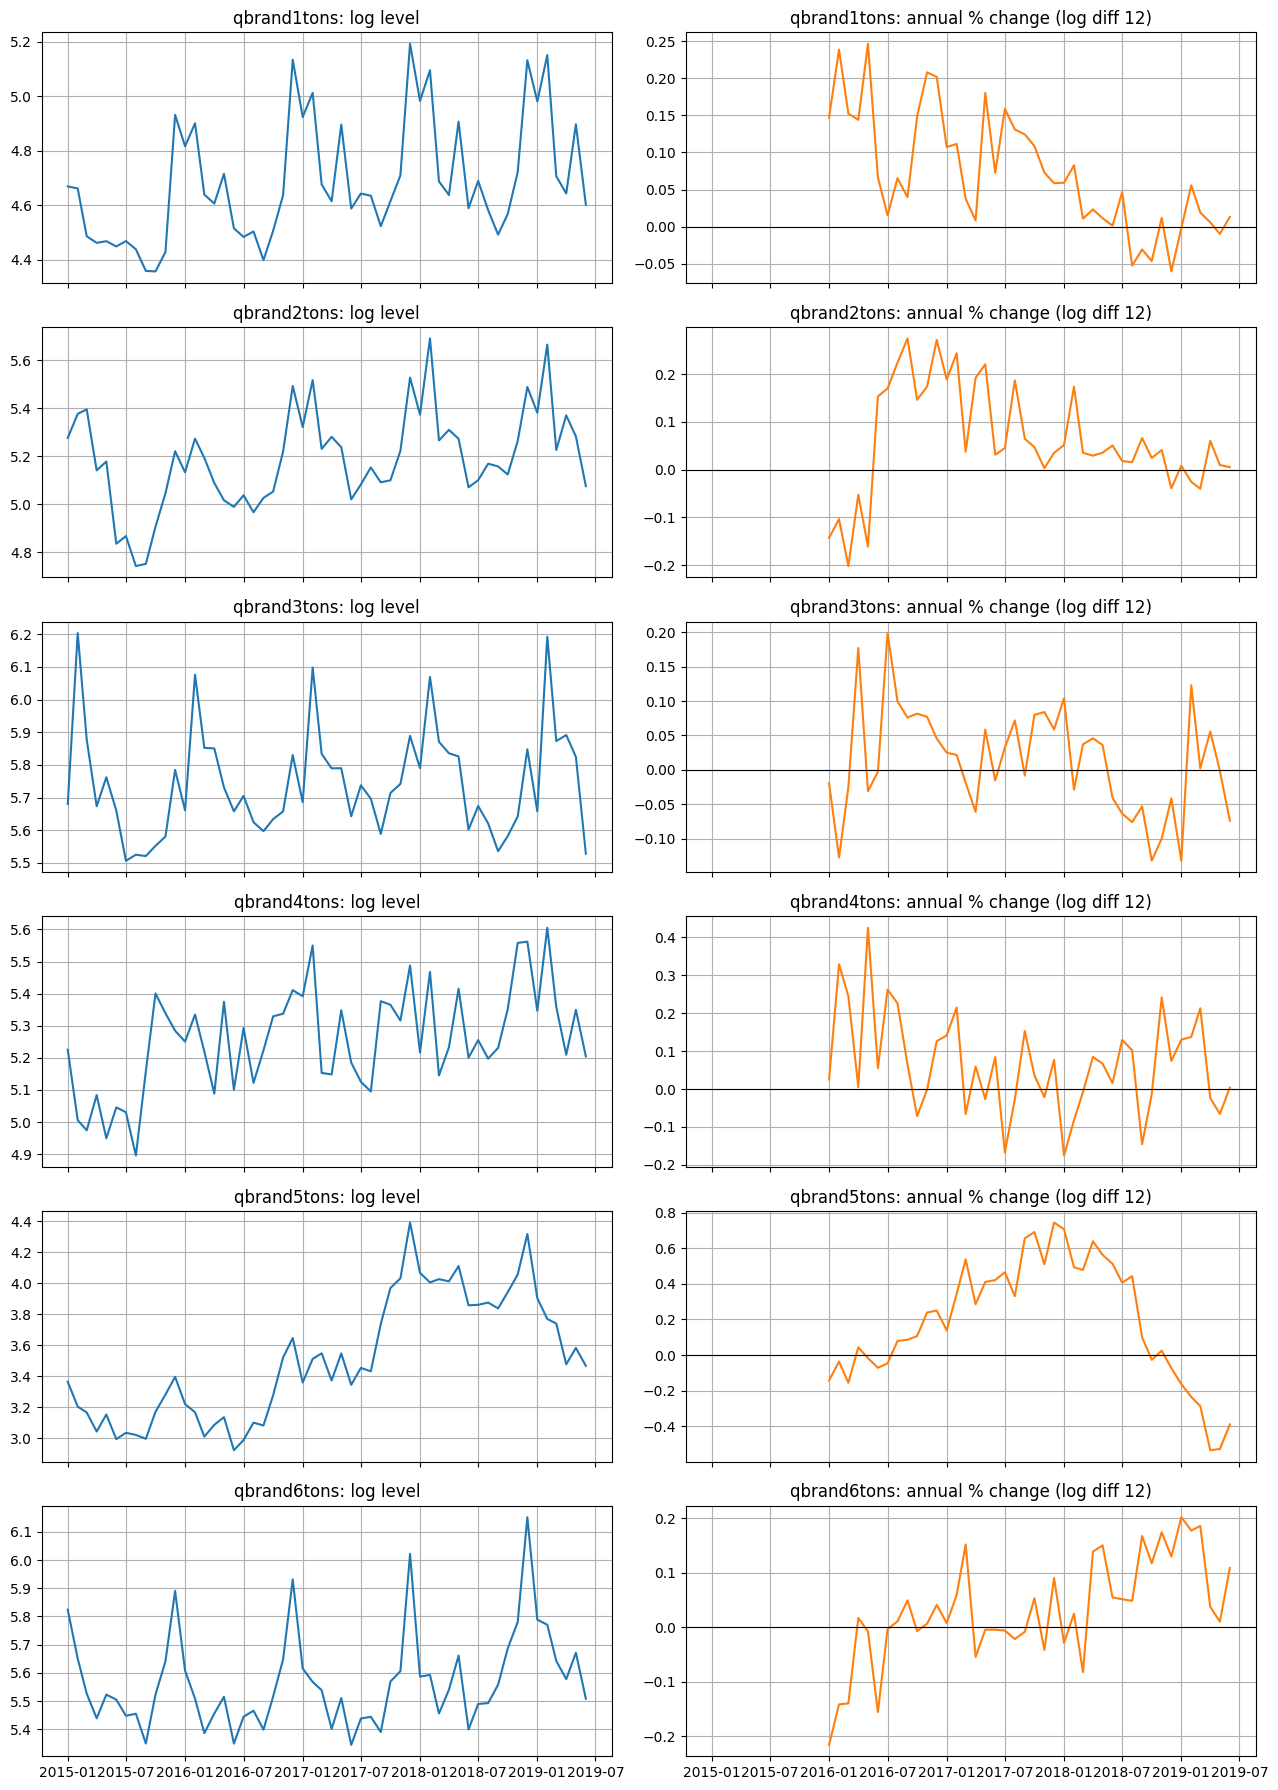

In [ ]:
# Gráficas de las seis marcas para entender los casos ambiguos a la izquierda el nivel en log, derecha el cambio % anual
fig, axes = plt.subplots(len(brand_cols), 2, figsize=(13, 3 * len(brand_cols)), sharex=True)
for i, col in enumerate(brand_cols):
    axes[i, 0].plot(ln_sales.index, ln_sales[col])
    axes[i, 0].set_title(f'{col}: log level')
    axes[i, 1].plot(ysales_growth.index, ysales_growth[col], color='tab:orange')
    axes[i, 1].axhline(0, color='black', linewidth=0.8)
    axes[i, 1].set_title(f'{col}: annual % change (log diff 12)')
    for ax in axes[i]:
        ax.grid(True)
plt.tight_layout()
plt.show()

### 3. Decisión por marca

En la tabla se ve que el nivel en logaritmo de cinco de las seis marcas no rechaza la raíz unitaria (p-values entre 0.89 y 0.99) por lo que esas no se deberían modelar en niveles, la excepción es la marca 4 cuyo nivel con constante y tendencia sí rechaza (p = 0.001) es decir que es estacionaria alrededor de una tendencia.

El cambio porcentual mensual solo rechaza la raíz unitaria en las marcas 3, 4 y 6 pero como todavía tiene estacionalidad la prueba ADF puede salir distorsionada, por eso para modelar me quedaría con el cambio porcentual anual (diferencia estacional del logaritmo) en la mayoría de las marcas aunque no todas llevan a la misma decisión.

- Marca 1: usaría el cambio porcentual anual pero probaría una diferencia extra, ya que la ADF del cambio anual no rechaza (0.117) y la KPSS sí rechaza (0.01 o menos) por lo que las dos pruebas dicen que no es estacionaria, y en la gráfica se ve que el crecimiento anual va bajando de casi 20% en 2016 a cerca de 0% en 2019.
- Marca 2: usaría el cambio porcentual anual, ya que el nivel claramente no es estacionario y aunque la ADF del cambio anual no rechaza (0.118) la KPSS tampoco rechaza (0.10 o más) por lo que es un caso ambiguo por falta de datos y no una prueba de que no sea estacionaria.
- Marca 3: usaría el cambio porcentual anual, ya que aunque la ADF no rechaza (0.336) la KPSS tampoco (0.10 o más) así que es el mismo caso ambiguo que la marca 2, y aunque el cambio mensual sí rechaza (0.007) todavía tiene estacionalidad.
- Marca 4: usaría el cambio porcentual anual por la estacionalidad, aunque es la única marca donde todas las versiones salen estacionarias y la ADF con KPSS confirma que el cambio anual es estacionario (ADF de 0.000 y KPSS de 0.08).
- Marca 5: usaría el cambio porcentual anual, ya que la ADF rechaza (0.021) y la KPSS no (0.10 o más) por lo que las pruebas dicen que es estacionario, aunque con cuidado porque solo usó 33 observaciones y en la gráfica el crecimiento sube de 0% a casi 70% y luego cae a -50%, lo cual no se ve como una serie que regresa a su media.
- Marca 6: usaría el cambio porcentual anual, ya que la ADF rechaza (0.032) pero la KPSS también rechaza (0.01 o menos) por lo que es un caso ambiguo, y es la marca que se modela en el Challenge 3.

Una marca ambigua es la 6, donde la ADF da 0.032 y la KPSS da 0.01 o menos, es decir que la ADF dice que es estacionaria y la KPSS dice que no, que según la tabla del workshop puede ser por un cambio estructural o por memoria larga.

Viendo su gráfica creo que la causa es que el crecimiento anual no se queda alrededor de una media sino que va subiendo de cerca de -20% a principios de 2016 a cerca de 20% en 2019, es decir que las ventas se fueron acelerando, y además solo hay unos 40 datos en el cambio anual por lo que las pruebas tienen poco poder. Algo parecido pasa con la marca 1 pero al revés, ya que su crecimiento va bajando.

### 4. Vida media de un choque con datos mensuales

In [ ]:
phis = [0.5, 0.9, 0.99]
half_life_ch1 = pd.DataFrame({
    'phi1': phis,
    'half-life (months)': [np.log(0.5) / np.log(p) for p in phis],
    'share of shock left after 12 months': [p ** 12 for p in phis],
})
half_life_ch1['half-life (years)'] = half_life_ch1['half-life (months)'] / 12
half_life_ch1.round(3)

,phi1,half-life (months),share of shock left after 12 months,half-life (years)
0,0.50,1.000,0.000,0.083
1,0.90,6.579,0.282,0.548
2,0.99,68.968,0.886,5.747


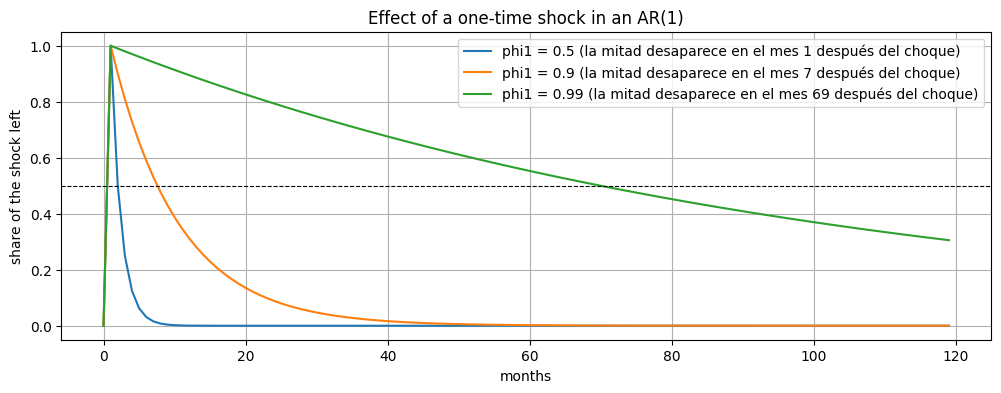

In [ ]:
# Comprobación con la simulación de clase: un solo choque de tamaño 1 en el mes 1 y sin constante,
# así la serie simulada es exactamente lo que queda del choque en cada mes
months = 120
impulse = np.zeros(months)
impulse[1] = 1.0
fig, ax = plt.subplots(figsize=(12, 4))
for p in phis:
    path = simulate_ar1(0, p, impulse)
    first_half = int(np.argmax(path[1:] <= 0.5)) + 1            # primer mes en que queda la mitad o menos
    ax.plot(path, label=f'phi1 = {p} (la mitad desaparece en el mes {first_half - 1} después del choque)')
ax.axhline(0.5, color='black', linestyle='--', linewidth=0.8)
ax.set_xlabel('months')
ax.set_ylabel('share of the shock left')
ax.set_title('Effect of a one-time shock in an AR(1)')
ax.legend()
ax.grid(True)
plt.show()

La vida media se calcula como el logaritmo de 0.5 entre el logaritmo de phi1, por lo que con phi1 de 0.5 la mitad de un choque desaparece en 1 mes, con 0.9 tarda unos 6.6 meses y con 0.99 tarda unos 69 meses, es decir casi 6 años.

En la simulación con un solo choque se ve lo mismo, ya que la línea de cada serie cruza la mitad justo alrededor de esos meses.

Pensando en las ventas de una marca, si phi1 fuera 0.5 una promoción o una caída inesperada de ventas se olvidaría casi en un mes, por lo que para pronosticar a varios meses casi no importaría lo que pasó este mes.

Con 0.9 el efecto duraría más de un trimestre, por lo que un mes malo todavía se notaría en el pronóstico de los siguientes meses, y con 0.99 el choque sería prácticamente permanente, ya que a un año todavía queda cerca del 89% del efecto, lo cual se parece mucho a una caminata aleatoria y haría muy difícil distinguirla de una serie con raíz unitaria.

# Parte B. Regresión espuria y cointegración

## Regresión espuria: una simulación

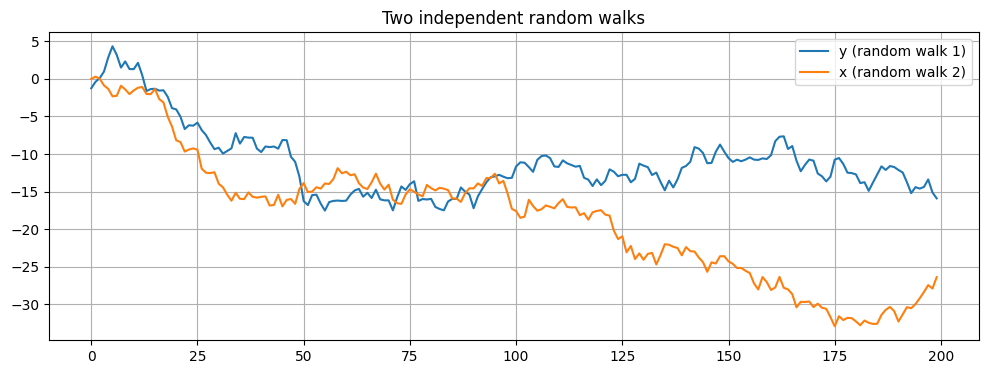

In [ ]:
rng = np.random.default_rng(7)
n = 200
x_rw = np.cumsum(rng.normal(0, 1, n))
y_rw = np.cumsum(rng.normal(0, 1, n))
sim_df = pd.DataFrame({'y': y_rw, 'x': x_rw})

plt.figure(figsize=(12, 4))
plt.plot(sim_df['y'], label='y (random walk 1)')
plt.plot(sim_df['x'], label='x (random walk 2)')
plt.title('Two independent random walks')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
spur = smf.ols('y ~ x', data=sim_df).fit()
print(spur.summary().tables[1])
print(f"R-squared = {spur.rsquared:.3f}")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -5.8696      0.686     -8.552      0.000      -7.223      -4.516
x              0.2813      0.034      8.285      0.000       0.214       0.348
R-squared = 0.257


Aquí simulamos dos caminatas aleatorias que se construyeron con choques aleatorios distintos, por lo que no tienen ninguna relación entre ellas, y aun así al hacer la regresión de una contra la otra la pendiente salió de 0.28 con un estadístico t de 8.3 y un p-value de prácticamente cero, es decir que la regresión dice que hay una relación muy significativa cuando en realidad no existe.

A esto se le llama regresión espuria (spurious regression), y pasa porque las dos series deambulan sin regresar a ninguna media, por lo que en algunos tramos parecen moverse juntas solo por casualidad.

In [ ]:
def spurious_rate(n, reps=500, differences=False, seed=0):
    """Proporción de regresiones con p<0.05 entre dos caminatas aleatorias INDEPENDIENTES."""
    rng = np.random.default_rng(seed)
    count = 0
    for _ in range(reps):
        x = np.cumsum(rng.normal(size=n))
        y = np.cumsum(rng.normal(size=n))
        if differences:
            x, y = np.diff(x), np.diff(y)
        p = sm.OLS(y, sm.add_constant(x)).fit().pvalues[1]
        count += p < 0.05
    return count / reps

spurious_table = pd.DataFrame({
    'n': [50, 200, 1000],
    'p<0.05 in LEVELS': [spurious_rate(k) for k in [50, 200, 1000]],
    'p<0.05 in DIFFERENCES': [spurious_rate(k, differences=True) for k in [50, 200, 1000]],
})
spurious_table

,n,p<0.05 in LEVELS,p<0.05 in DIFFERENCES
0,50,0.700,0.072
1,200,0.818,0.050
2,1000,0.922,0.050


In [ ]:
rate_200 = float(spurious_table.loc[spurious_table['n'] == 200, 'p<0.05 in LEVELS'].iloc[0])
print(f"With n = 200, levels regressions are 'significant' {rate_200:.1%} of the time (should be about 5%)")

With n = 200, levels regressions are 'significant' 81.8% of the time (should be about 5%)


In [ ]:
from statsmodels.stats.stattools import durbin_watson
print(f"R-squared = {spur.rsquared:.3f},  Durbin-Watson = {durbin_watson(spur.resid):.3f}")

R-squared = 0.257,  Durbin-Watson = 0.061


Al repetir el experimento 500 veces se ve que no fue mala suerte, ya que en niveles la regresión sale significativa el 70% de las veces con 50 datos, el 82% con 200 y el 92% con 1000, cuando si la prueba funcionara bien debería pasar solo alrededor del 5% de las veces porque la pendiente verdadera es cero, y el problema empeora con más datos.

En cambio en diferencias, que sí son estacionarias, la tasa queda cerca del 5%.

Esto pasa porque si las dos series son caminatas aleatorias independientes, el error de la regresión también es una caminata aleatoria, por lo que no es estacionario y está muy autocorrelacionado, lo cual rompe los supuestos de MCO y hace que los estadísticos t ya no sigan una distribución t y crezcan con n.

Una señal de alerta es que la R cuadrada sea mayor que el estadístico de Durbin-Watson, y aquí la R cuadrada es 0.257 y el Durbin-Watson es 0.061, el cual al estar tan cerca de cero indica que los residuales tienen una autocorrelación positiva muy fuerte.

## Regresión espuria con datos reales (Banco Mundial)

In [ ]:
def get_wb(indicator, country='MEX', start=1980, end=2024):
    """Descarga un indicador del Banco Mundial para un país como una Serie de pandas."""
    url = (f"https://api.worldbank.org/v2/country/{country}/indicator/{indicator}"
           f"?format=json&date={start}:{end}&per_page=500")
    js = requests.get(url, timeout=60).json()                          # la API regresa [metadatos, datos]
    s = pd.Series({int(d['date']): d['value'] for d in js[1]}, dtype=float)
    return s.sort_index()

wb = pd.DataFrame({
    'infant_mortality': get_wb('SP.DYN.IMRT.IN'),     # muertes por cada 1,000 nacidos vivos
    'exports': get_wb('TX.VAL.MRCH.XD.WD'),           # índice del valor de exportaciones de mercancías
}).dropna()
wb.tail()

,infant_mortality,exports
2020,13.4,109.6
2021,13.1,130.1
2022,12.8,151.8
2023,12.4,155.8
2024,12.1,162.2


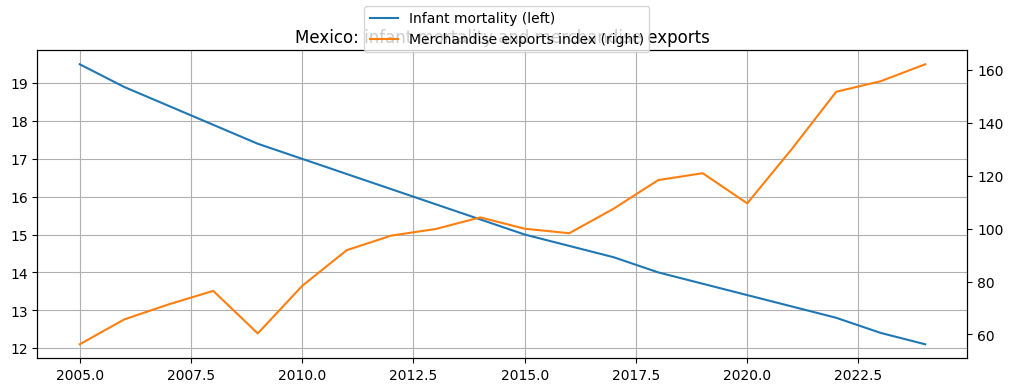

In [ ]:
fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(wb.index, wb['infant_mortality'], color='tab:blue', label='Infant mortality (left)')
ax2 = ax1.twinx()
ax2.plot(wb.index, wb['exports'], color='tab:orange', label='Merchandise exports index (right)')
ax1.set_title('Mexico: infant mortality and merchandise exports')
fig.legend(loc='upper center')
ax1.grid(True)
plt.show()

In [ ]:
wb_log = np.log(wb)
reg_levels = smf.ols('exports ~ infant_mortality', data=wb_log).fit()
reg_diffs = smf.ols('exports ~ infant_mortality', data=wb_log.diff().dropna()).fit()

wb_results = pd.DataFrame({
    'slope': [reg_levels.params['infant_mortality'], reg_diffs.params['infant_mortality']],
    'p-value': [reg_levels.pvalues['infant_mortality'], reg_diffs.pvalues['infant_mortality']],
    'R-squared': [reg_levels.rsquared, reg_diffs.rsquared],
    'Durbin-Watson': [durbin_watson(reg_levels.resid), durbin_watson(reg_diffs.resid)],
}, index=['levels (logs)', 'differences (% changes)']).round(4)
wb_results

,slope,p-value,R-squared,Durbin-Watson
levels (logs),-2.0169,0.0000,0.9212,1.5875
differences (% changes),3.4032,0.6791,0.0103,2.2280


La mortalidad infantil y las exportaciones de México no deberían tener una relación directa, y aun así la regresión en niveles encontró una pendiente de -2.02 con un p-value de cero y una R cuadrada de 0.92, es decir que parecería que cuando baja la mortalidad suben las exportaciones.

No tiene sentido que una menor mortalidad cause más exportaciones, lo que pasa es que las dos series siguen la tendencia de largo plazo del desarrollo del país, una baja y la otra sube con los años, por lo que la regresión en niveles solo captura esa tendencia común.

En diferencias la relación desaparece, ya que el p-value sube a 0.68 y la R cuadrada baja a 0.01.

Algo que noté es que aquí la regla de la R cuadrada mayor que el Durbin-Watson no se cumple (0.92 contra 1.59), por lo que esa regla es solo una señal y no una prueba, y lo que realmente decide si es espuria es la prueba de cointegración de más abajo.

## Cointegración

Dos series están cointegradas cuando cada una es no estacionaria (tiene raíz unitaria, es decir es I(1)), pero existe una combinación lineal de ellas, que son los residuales de la regresión en niveles, que sí es estacionaria (I(0)).

El ejemplo clásico es el de una borracha caminando a su casa con su perro, donde cada uno deambula como una caminata aleatoria por lo que no se puede predecir dónde va a estar ninguno, pero nunca se alejan demasiado uno del otro, ya que cuando se separan el perro regresa o ella lo llama, es decir que la distancia entre ellos es estacionaria y hay un equilibrio de largo plazo.

Cuando dos series están cointegradas la regresión en niveles no es espuria, ya que lo que estima es esa relación de equilibrio.

Esto corrige lo que tenía en mis notas, ya que la cointegración no mide qué tanto están conectadas como una correlación, sino que es una propiedad que se prueba y la respuesta es sí o no.

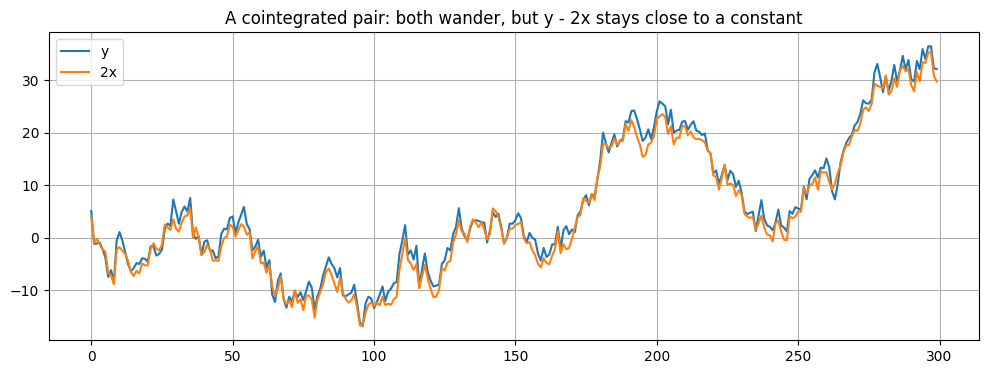

In [ ]:
rng = np.random.default_rng(3)
n = 300
x_c = np.cumsum(rng.normal(0, 1, n))                       # caminata aleatoria
u_c = simulate_ar1(0, 0.5, rng.normal(0, 1, n))           # desviación estacionaria
y_c = 1 + 2 * x_c + u_c                                    # cointegrada con x
coint_df = pd.DataFrame({'y': y_c, 'x': x_c})

plt.figure(figsize=(12, 4))
plt.plot(coint_df['y'], label='y')
plt.plot(2 * coint_df['x'], label='2x')
plt.title('A cointegrated pair: both wander, but y - 2x stays close to a constant')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from statsmodels.tsa.stattools import coint

# Forma incorrecta (para comparar): ADF simple sobre los residuales
resid_c = smf.ols('y ~ x', data=coint_df).fit().resid
p_wrong = adfuller(resid_c, regression='n')[1]

# Forma correcta: Engle-Granger con los valores críticos adecuados
eg_stat, p_eg, eg_crit = coint(coint_df['y'], coint_df['x'], trend='c')
print(f"Plain ADF on residuals (wrong critical values): p = {p_wrong:.4f}")
print(f"Engle-Granger test (coint):                     p = {p_eg:.4f}")

Plain ADF on residuals (wrong critical values): p = 0.0000
Engle-Granger test (coint):                     p = 0.0000


/tmp/ipykernel_502/2901724006.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_wrong = adfuller(resid_c, regression='n')[1]


In [ ]:
p_eg_spur = coint(sim_df['y'], sim_df['x'], trend='c')[1]
print(f"Engle-Granger p-value, independent random walks: {p_eg_spur:.4f}")

Engle-Granger p-value, independent random walks: 0.4547


In [ ]:
p_eg_wb = coint(wb_log['exports'], wb_log['infant_mortality'], trend='c')[1]
wb_verdict = "are cointegrated, so the regression in levels could be interpreted as a long-run relationship" if p_eg_wb < 0.05 else "are NOT cointegrated, so the regression in levels is spurious"
print(f"Engle-Granger p-value: {p_eg_wb:.4f}")
print(f"The two series {wb_verdict}")

Engle-Granger p-value: 0.9859
The two series are NOT cointegrated, so the regression in levels is spurious


La prueba de Engle-Granger tiene tres pasos, primero verificar que las dos series son I(1), es decir que la ADF no rechaza en niveles pero sí en diferencias, luego correr la regresión en niveles, y al final probar si los residuales son estacionarios.

La sutileza es que MCO escoge los coeficientes justo para que los residuales sean lo más pequeños posible, por lo que se ven más estacionarios de lo que son, y si usáramos los valores críticos normales de la ADF rechazaríamos de más, por eso la función coint usa los valores críticos de Engle-Granger, que son más exigentes.

La hipótesis nula de coint es que no hay cointegración, por lo que si el p-value es menor que 0.05 decimos que sí están cointegradas.

En el par simulado la cointegración se detecta claramente con un p-value de 0, en las caminatas independientes del inicio el p-value fue de 0.45 por lo que no están cointegradas como era de esperarse, y en la mortalidad infantil contra las exportaciones el p-value fue de 0.99, por lo que no están cointegradas y la regresión en niveles es espuria, aunque con pocos datos anuales la prueba tiene poco poder y por eso también hay que usar la lógica económica.

## Un par cointegrado real: WTI contra Brent

In [ ]:
import os
import time
import yfinance as yf

def get_yahoo(ticker, start='2000-01-01', end='2026-01-01', cache_dir='yahoo_data', retries=3):
    """Descarga precios de cierre diarios de Yahoo Finance como una Serie de pandas.

    - `end` NO se incluye (convención de yfinance).
    - Si Yahoo no regresa datos, espera y vuelve a intentar.
    - La primera descarga exitosa se guarda en la carpeta `yahoo_data/`; las siguientes ejecuciones leen
      ese archivo y no necesitan internet. Borra la carpeta para descargar datos nuevos.
    """
    os.makedirs(cache_dir, exist_ok=True)
    name = ticker.replace('^', '').replace('=', '_')
    cache_file = os.path.join(cache_dir, f"{name}_{start}_{end}.csv")
    if os.path.exists(cache_file):
        return pd.read_csv(cache_file, index_col=0, parse_dates=True).iloc[:, 0].rename(ticker)
    for attempt in range(1, retries + 1):
        try:
            s = yf.download(ticker, start=start, end=end, auto_adjust=True, progress=False)['Close']
            s = s.squeeze('columns').dropna() if isinstance(s, pd.DataFrame) else s.dropna()
            if len(s) > 0:
                s = s.rename(ticker)
                s.index.name = 'date'
                s.to_csv(cache_file)
                return s
            print(f"Attempt {attempt}/{retries}: Yahoo returned no data for {ticker}")
        except Exception as e:
            print(f"Attempt {attempt}/{retries} for {ticker} failed: {type(e).__name__}")
        time.sleep(5 * attempt)
    raise RuntimeError(f"Could not download {ticker} from Yahoo Finance. Try again later.")

oil_daily = pd.DataFrame({'wti': get_yahoo('CL=F', start='2008-01-01', end='2026-01-01'),
                          'brent': get_yahoo('BZ=F', start='2008-01-01', end='2026-01-01')})

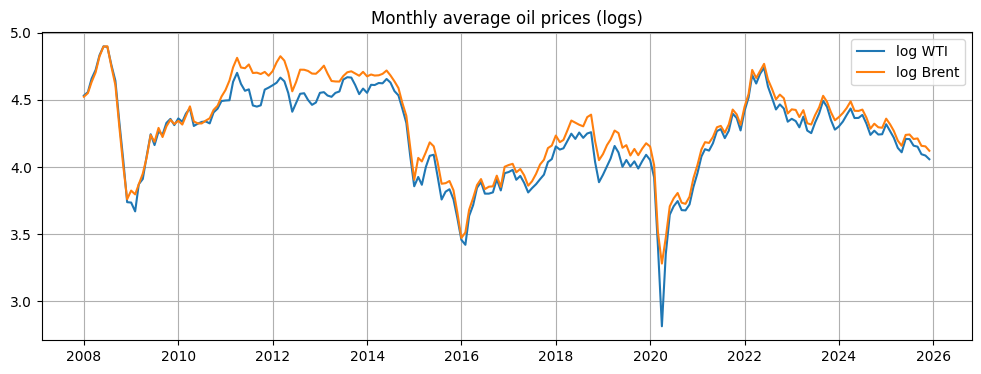

In [ ]:
oil = oil_daily.resample('MS').mean().loc[:'2025-12-01'].dropna()   # promedios mensuales: evita el WTI negativo de abril 2020
ln_oil = np.log(oil)

plt.figure(figsize=(12, 4))
plt.plot(ln_oil.index, ln_oil['wti'], label='log WTI')
plt.plot(ln_oil.index, ln_oil['brent'], label='log Brent')
plt.title('Monthly average oil prices (logs)')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Paso 0: ¿las dos series son I(1)? (ADF en niveles y en primeras diferencias)
oil_i1 = pd.DataFrame({
    'p-value ADF level (c)': [adf_test(ln_oil[c], 'c')['p-value'] for c in ['wti', 'brent']],
    'p-value ADF 1st diff (c)': [adf_test(ln_oil[c].diff(), 'c')['p-value'] for c in ['wti', 'brent']],
}, index=['log WTI', 'log Brent']).round(4)
oil_i1

/tmp/ipykernel_502/2128191227.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(x.dropna(), regression=regression, autolag='AIC')
/tmp/ipykernel_502/2128191227.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(x.dropna(), regression=regression, autolag='AIC')
/tmp/ipykernel_502/2128191227.py:5: FutureWarning: adfuller currently returns a 

,p-value ADF level (c),p-value ADF 1st diff (c)
log WTI,0.0224,0.0
log Brent,0.0428,0.0


El WTI y el Brent son dos tipos de petróleo que se pueden sustituir, por lo que si uno se vuelve mucho más barato los compradores se cambian a él y el arbitraje cierra la diferencia, por eso esperamos que estén cointegrados.

Usamos promedios mensuales de los futuros, lo cual también evita el 20 de abril de 2020 cuando el WTI cerró en -37 dólares y el logaritmo de un negativo no existe.

Algo que no cuadra es que en el paso 0 esperábamos p-values altos en niveles para poder decir que las series son I(1), pero salieron 0.022 y 0.043, los cuales son menores que 0.05, por lo que con la regla de la Parte A la ADF sí rechaza la raíz unitaria en niveles.

Esto podría ser por el poco poder de la prueba, por haber usado 'c' y no 'ct', o por los cambios estructurales como el de 2011 a 2014, pero es algo que vale la pena preguntar en clase.

In [ ]:
# Paso 1: regresión de largo plazo en niveles (logs)
oil_lr = smf.ols('brent ~ wti', data=ln_oil).fit()
beta_oil = float(oil_lr.params['wti'])
print(oil_lr.summary().tables[1])

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.1615      0.054      2.976      0.003       0.055       0.268
wti            0.9789      0.013     76.613      0.000       0.954       1.004


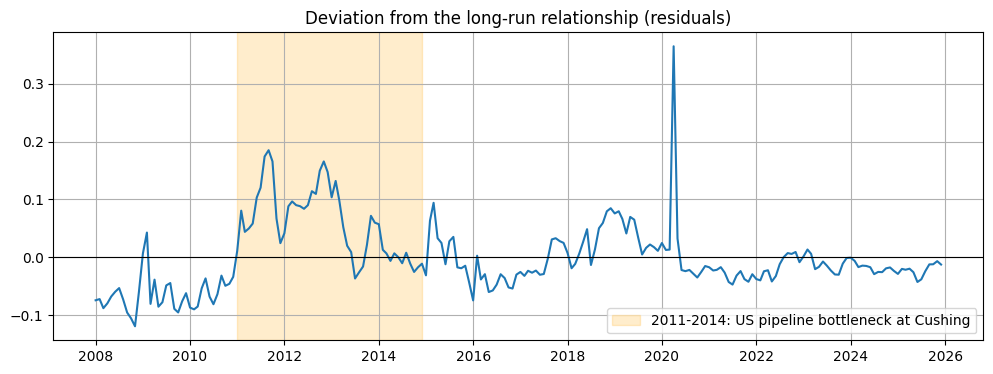

Engle-Granger p-value: 0.0143 -> reject the null of no cointegration


In [ ]:
# Paso 2: ¿la desviación del equilibrio (spread) es estacionaria?
spread = oil_lr.resid

plt.figure(figsize=(12, 4))
plt.plot(spread.index, spread)
plt.axhline(0, color='black', linewidth=0.8)
plt.axvspan(pd.Timestamp('2011-01-01'), pd.Timestamp('2014-12-01'), color='orange', alpha=0.2,
            label='2011-2014: US pipeline bottleneck at Cushing')
plt.title('Deviation from the long-run relationship (residuals)')
plt.legend()
plt.grid(True)
plt.show()

p_eg_oil = coint(ln_oil['brent'], ln_oil['wti'], trend='c')[1]
oil_verdict = "reject" if p_eg_oil < 0.05 else "cannot reject"
print(f"Engle-Granger p-value: {p_eg_oil:.4f} -> {oil_verdict} the null of no cointegration")

La elasticidad de largo plazo salió de 0.979, es decir que un precio del WTI 1% más alto va de la mano con un Brent alrededor de 0.98% más alto en el largo plazo, y la prueba de Engle-Granger dio un p-value de 0.014, por lo que rechazamos que no haya cointegración y decimos que sí están cointegradas al 5%.

En la gráfica del spread se ve que entre 2011 y 2014 la desviación se alejó mucho de cero por mucho tiempo, ya que la producción de petróleo de Estados Unidos creció muy rápido y no podía llegar a la costa por los cuellos de botella en los oleoductos, por lo que el WTI se volvió mucho más barato que el Brent, y este tipo de cambio estructural hace que el spread se vea menos estacionario y le quita poder a la prueba.

## Corrección de errores: cómo se cierra la brecha

In [ ]:
ecm_df = pd.DataFrame({'d_brent': ln_oil['brent'].diff(),
                       'd_wti': ln_oil['wti'].diff(),
                       'u_lag': spread.shift(1)}).dropna()      # desviación del equilibrio del mes pasado
ecm = smf.ols('d_brent ~ u_lag + d_wti', data=ecm_df).fit()
gamma = float(ecm.params['u_lag'])
gamma_p = float(ecm.pvalues['u_lag'])
print(ecm.summary().tables[1])
print(f"gamma = {gamma:.4f} (p-value = {gamma_p:.4f})")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0001      0.002     -0.054      0.957      -0.005       0.004
u_lag         -0.1742      0.038     -4.558      0.000      -0.250      -0.099
d_wti          0.7870      0.022     36.603      0.000       0.745       0.829
gamma = -0.1742 (p-value = 0.0000)


En el modelo de corrección de errores (ECM) el cambio del Brent depende de la desviación del equilibrio del mes pasado y del cambio del WTI del mismo mes, y si gamma es negativa quiere decir que cuando el Brent está por encima de su equilibrio con el WTI el siguiente mes tiende a bajar, es decir que la brecha se va cerrando.

Gamma salió de -0.174 con un p-value de cero, por lo que cada mes se corrige alrededor del 17% de la desviación, y delta salió de 0.787, lo que significa que en el mismo mes el Brent se mueve 0.79% por cada 1% que se mueve el WTI.

Con la fórmula del Challenge 2 la vida media de una desviación sería el logaritmo de 0.5 entre el logaritmo de 1 más gamma, que da unos 3.6 meses.

## Por qué esto importa para IA y machine learning

Estas ideas aplican a cualquier modelo entrenado con series de tiempo y no solo a la regresión lineal, ya que dos variables con tendencia siempre se ven muy correlacionadas, por lo que un modelo puede verse excelente dentro de la muestra y fallar fuera de ella, y seleccionar variables filtrando por correlación es peligroso con datos con tendencia.

Además si la serie no es estacionaria los datos de prueba vienen de una distribución distinta a los de entrenamiento (distribution shift), lo cual rompe el supuesto básico de la mayoría de los modelos de ML, y los modelos de árboles como random forest o gradient boosting no pueden predecir valores fuera del rango que vieron, por lo que conviene modelar tasas de crecimiento y luego regresar a niveles.

También las divisiones de entrenamiento y prueba tienen que respetar el orden del tiempo, ya que revolver los datos filtra información del futuro (leakage), y por último cuando dos series están cointegradas la desviación del equilibrio es una variable estacionaria muy útil, que es la base del pairs trading en finanzas.

# Challenge 2 (Parte B)

### 1. Experimento de regresión espuria

In [ ]:
def spurious_rate2(n, case='levels', reps=500, seed=0):
    """Proporción de regresiones con p<0.05 entre dos series INDEPENDIENTES.

    case = 'levels' -> dos caminatas aleatorias en niveles
    case = 'diff'   -> las mismas caminatas en primeras diferencias
    case = 'ar1'    -> dos AR(1) estacionarios con phi1 = 0.5, en niveles
    """
    rng = np.random.default_rng(seed)
    count = 0
    for _ in range(reps):
        if case == 'ar1':
            x = simulate_ar1(0, 0.5, rng.normal(size=n))
            y = simulate_ar1(0, 0.5, rng.normal(size=n))
        else:
            x = np.cumsum(rng.normal(size=n))
            y = np.cumsum(rng.normal(size=n))
            if case == 'diff':
                x, y = np.diff(x), np.diff(y)
        p = sm.OLS(y, sm.add_constant(x)).fit().pvalues[1]
        count += p < 0.05
    return count / reps

n_list = [25, 50, 100, 250, 500, 1000]
ch2_rates = pd.DataFrame({
    'n': n_list,
    '(a) random walks, levels': [spurious_rate2(k, 'levels') for k in n_list],
    '(b) random walks, differences': [spurious_rate2(k, 'diff') for k in n_list],
    '(c) stationary AR(1) phi1=0.5, levels': [spurious_rate2(k, 'ar1') for k in n_list],
}).set_index('n')
ch2_rates

,"(a) random walks, levels","(b) random walks, differences","(c) stationary AR(1) phi1=0.5, levels"
n,,,
25,0.504,0.048,0.128
50,0.700,0.072,0.150
100,0.746,0.042,0.114
250,0.854,0.056,0.148
500,0.884,0.042,0.116
1000,0.922,0.050,0.122


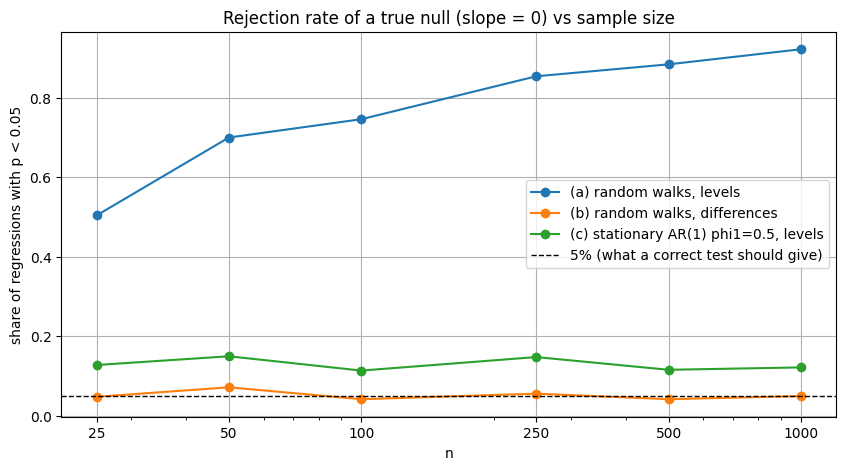

In [ ]:
ax = ch2_rates.plot(marker='o', figsize=(10, 5), logx=True)   # eje x en escala logarítmica porque n crece mucho
ax.axhline(0.05, color='black', linestyle='--', linewidth=1, label='5% (what a correct test should give)')
ax.set_xticks(n_list)
ax.set_xticklabels(n_list)
ax.set_ylabel('share of regressions with p < 0.05')
ax.set_title('Rejection rate of a true null (slope = 0) vs sample size')
ax.legend()
ax.grid(True)
plt.show()

En el caso (a), con dos caminatas aleatorias en niveles, la tasa de rechazo pasó de 50% con 25 datos a 92% con 1000 datos, es decir que entre más datos tenemos más seguido la regresión dice que hay una relación que no existe.

Esto pasa porque el error de la regresión también es una caminata aleatoria, por lo que su varianza crece con el tiempo y los estadísticos t ya no siguen una distribución t sino que crecen con n, entonces con más datos el t sale cada vez más grande aunque la pendiente verdadera sea cero.

En el caso (b), con las mismas caminatas en diferencias, la tasa queda cerca del 5% (entre 4.2% y 7.2%), ya que las diferencias de una caminata aleatoria son puro ruido y son estacionarias, por lo que la prueba funciona como debería.

En el caso (c), con dos AR(1) estacionarios, la tasa queda entre 11% y 15% sin importar n, la cual es más alta que el 5% porque las series sí están autocorrelacionadas y MCO subestima los errores estándar, pero es mucho mejor que el caso (a) y no empeora con más datos, ya que al ser estacionarias regresan a su media y la pendiente estimada sí se va acercando a cero conforme hay más datos, mientras que en las caminatas aleatorias la pendiente nunca se estabiliza.

### 2. Cointegración: gasolina RBOB contra petróleo WTI

Months: 240 | from 2006-01 to 2025-12
Months with zero or negative averages (no log possible): 0


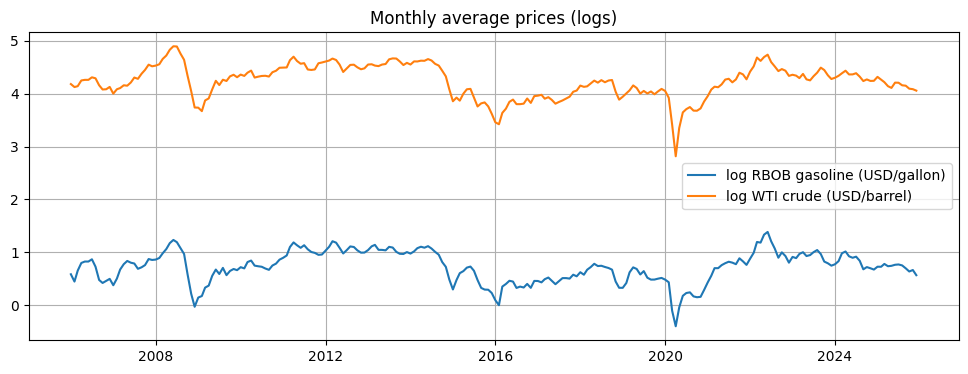

In [ ]:
# end='2026-01-01' porque yfinance NO incluye la fecha final, así llegamos hasta el 2025-12-31
fuel_daily = pd.DataFrame({'rbob': get_yahoo('RB=F', start='2006-01-01', end='2026-01-01'),   # dólares por galón
                           'wti': get_yahoo('CL=F', start='2006-01-01', end='2026-01-01')})   # dólares por barril
fuel = fuel_daily.resample('MS').mean().loc[:'2025-12-01'].dropna()
print("Months:", len(fuel), "| from", fuel.index[0].strftime('%Y-%m'), "to", fuel.index[-1].strftime('%Y-%m'))
print("Months with zero or negative averages (no log possible):", int((fuel <= 0).sum().sum()))
ln_fuel = np.log(fuel)

plt.figure(figsize=(12, 4))
plt.plot(ln_fuel.index, ln_fuel['rbob'], label='log RBOB gasoline (USD/gallon)')
plt.plot(ln_fuel.index, ln_fuel['wti'], label='log WTI crude (USD/barrel)')
plt.title('Monthly average prices (logs)')
plt.legend()
plt.grid(True)
plt.show()

Las dos series están en unidades distintas, la gasolina en dólares por galón y el petróleo en dólares por barril, pero al trabajar en logaritmos eso solo cambia la constante de la regresión y no la elasticidad, ya que el logaritmo de un precio multiplicado por un factor es el logaritmo del precio más el logaritmo del factor.

Por eso las dos series se ven separadas en la gráfica pero se mueven casi igual.

In [ ]:
# a) ¿Las dos series son I(1)? ADF en niveles (con 'c' y con 'ct') y en primeras diferencias
fuel_i1 = pd.DataFrame({
    'ADF p level (c)': [adf_test(ln_fuel[c], 'c')['p-value'] for c in ['rbob', 'wti']],
    'ADF p level (ct)': [adf_test(ln_fuel[c], 'ct')['p-value'] for c in ['rbob', 'wti']],
    'ADF p 1st diff (c)': [adf_test(ln_fuel[c].diff(), 'c')['p-value'] for c in ['rbob', 'wti']],
}, index=['log RBOB', 'log WTI']).round(4)
fuel_i1

/tmp/ipykernel_502/2128191227.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(x.dropna(), regression=regression, autolag='AIC')
/tmp/ipykernel_502/2128191227.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(x.dropna(), regression=regression, autolag='AIC')
/tmp/ipykernel_502/2128191227.py:5: FutureWarning: adfuller currently returns a 

,ADF p level (c),ADF p level (ct),ADF p 1st diff (c)
log RBOB,0.0010,0.0058,0.0
log WTI,0.0062,0.0223,0.0


Para decir que una serie es I(1) la ADF no debe rechazar en niveles pero sí en primeras diferencias.

En niveles usé 'c' y 'ct' porque los precios del petróleo no tienen una tendencia clara en todo el periodo, ya que suben y bajan mucho (2008, 2014, 2020, 2022), por lo que reporto las dos versiones, y en las diferencias usé 'c' porque los cambios porcentuales fluctúan alrededor de una media sin tendencia.

En niveles con 'c' los p-values fueron 0.001 para la gasolina y 0.006 para el WTI, con 'ct' fueron 0.006 y 0.022, y en diferencias fueron 0.000 en las dos, por lo que la ADF sí rechaza la raíz unitaria en niveles, es decir que en este periodo las dos series se comportan como estacionarias y no como I(1).

Esto es lo mismo que pasó con el WTI y el Brent en clase y rompe el primer paso de Engle-Granger, ya que la prueba supone que las dos series son I(1), así que el resultado de la cointegración hay que tomarlo con cuidado. Una explicación posible es que entre 2006 y 2025 los precios del petróleo suben y bajan pero siempre regresan a un rango parecido, por lo que la ADF los ve como si regresaran a una media.

Engle-Granger: stat = -1.849, p-value = 0.6057
Critical values (1%, 5%, 10%): [-3.943 -3.362 -3.062]
-> NOT cointegrated at 5%
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -3.0678      0.084    -36.623      0.000      -3.233      -2.903
wti            0.8948      0.020     45.349      0.000       0.856       0.934


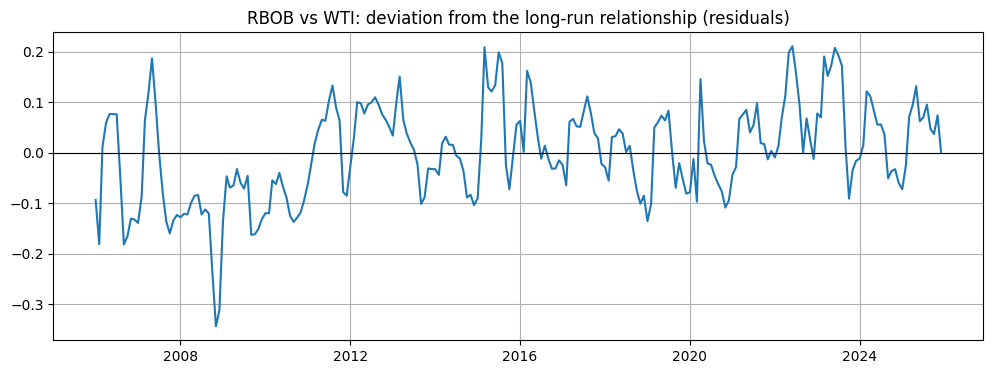

In [ ]:
# b) Prueba de Engle-Granger: H0 = no hay cointegración
eg_fuel_stat, p_eg_fuel, eg_fuel_crit = coint(ln_fuel['rbob'], ln_fuel['wti'], trend='c')
print(f"Engle-Granger: stat = {eg_fuel_stat:.3f}, p-value = {p_eg_fuel:.4f}")
print("Critical values (1%, 5%, 10%):", np.round(eg_fuel_crit, 3))
print("->", "cointegrated at 5%" if p_eg_fuel < 0.05 else "NOT cointegrated at 5%")

# Regresión de largo plazo (equilibrio) y su residual (spread)
fuel_lr = smf.ols('rbob ~ wti', data=ln_fuel).fit()
print(fuel_lr.summary().tables[1])
spread_fuel = fuel_lr.resid

plt.figure(figsize=(12, 4))
plt.plot(spread_fuel.index, spread_fuel)
plt.axhline(0, color='black', linewidth=0.8)
plt.title('RBOB vs WTI: deviation from the long-run relationship (residuals)')
plt.grid(True)
plt.show()

La prueba de Engle-Granger dio un estadístico de -1.85 y un p-value de 0.61, por lo que no rechazamos la hipótesis nula de no cointegración, es decir que según la prueba la gasolina y el WTI no están cointegradas, lo cual no esperaba porque el petróleo es el principal insumo de la gasolina.

La elasticidad de largo plazo salió de 0.895, es decir que cuando el WTI sube 1% la gasolina sube alrededor de 0.9% en el largo plazo.

En la gráfica de los residuales se ve que entre 2006 y 2010 la desviación casi siempre fue negativa (llegó hasta -0.34 a finales de 2008) y de 2011 en adelante casi siempre fue positiva, es decir que el spread cambió de nivel y no regresa a la misma media en todo el periodo. Esto coincide con 2011 a 2014, cuando el WTI se abarató por los cuellos de botella en los oleoductos y la gasolina quedó cara respecto a él, y es el mismo tipo de cambio estructural que vimos con el WTI y el Brent, el cual hace que el spread se vea no estacionario y le quita poder a la prueba.

In [ ]:
# c) Modelo de corrección de errores para la gasolina
ecm_fuel_df = pd.DataFrame({'d_rbob': ln_fuel['rbob'].diff(),
                            'd_wti': ln_fuel['wti'].diff(),
                            'u_lag': spread_fuel.shift(1)}).dropna()   # desviación del equilibrio del mes pasado
ecm_fuel = smf.ols('d_rbob ~ u_lag + d_wti', data=ecm_fuel_df).fit()
print(ecm_fuel.summary().tables[1])

gamma_fuel = float(ecm_fuel.params['u_lag'])
gamma_fuel_p = float(ecm_fuel.pvalues['u_lag'])
print(f"gamma = {gamma_fuel:.4f} (p-value = {gamma_fuel_p:.4f})")
if -1 < gamma_fuel < 0:                                            # la fórmula solo tiene sentido si gamma está entre -1 y 0
    hl_fuel = np.log(0.5) / np.log(1 + gamma_fuel)
    print(f"Half-life of a deviation = {hl_fuel:.2f} months")
else:
    print("gamma is not between -1 and 0, so the half-life formula does not apply")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0004      0.004      0.106      0.916      -0.007       0.007
u_lag         -0.1849      0.038     -4.834      0.000      -0.260      -0.110
d_wti          0.8740      0.035     25.216      0.000       0.806       0.942
gamma = -0.1849 (p-value = 0.0000)
Half-life of a deviation = 3.39 months


En el ECM de la gasolina gamma salió de -0.185 con un p-value de 0.000, por lo que es negativa y significativa, es decir que la gasolina sí corrige las desviaciones del equilibrio con el WTI.

Esto quiere decir que cada mes se corrige alrededor del 18% de la desviación, y con la fórmula de la vida media, que es el logaritmo de 0.5 entre el logaritmo de 1 más gamma, la mitad de una desviación desaparece en unos 3.4 meses.

Por ejemplo si la gasolina queda muy cara respecto al petróleo, en unos 3.4 meses ya se cerró la mitad de esa brecha.

El coeficiente de d_wti salió de 0.874, que es el efecto de corto plazo, es decir que en el mismo mes en que el WTI sube 1% la gasolina sube alrededor de 0.87%.

Lo raro es que el ECM dice que sí hay corrección hacia un equilibrio pero Engle-Granger dice que no hay cointegración, y creo que se explica por el cambio de nivel del spread alrededor de 2011, ya que la gasolina sí regresa al equilibrio en el corto plazo pero el equilibrio mismo se movió, por lo que la prueba de los residuales no encuentra una sola media. Es algo que vale la pena preguntar en clase.

### 3. Un par que no debería estar cointegrado: WTI contra el bono del Tesoro a 10 años

count    240.000
mean       2.900
std        1.121
min        0.615
25%        1.996
50%        2.743
75%        3.790
max        5.107
Name: ^TNX, dtype: float64


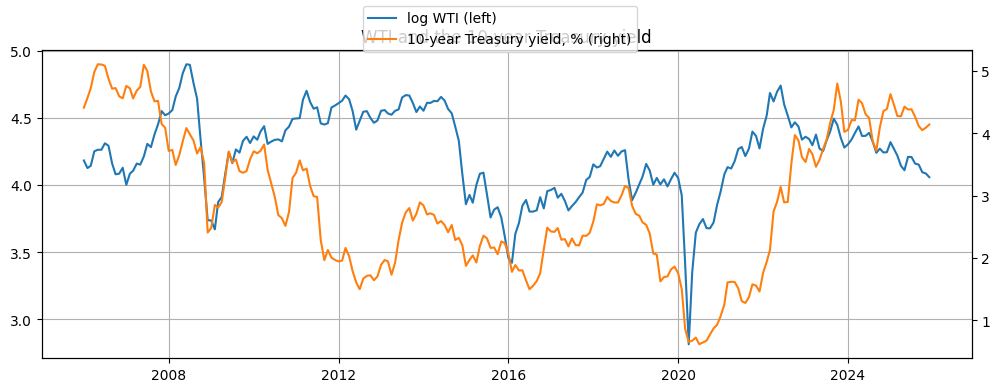

In [ ]:
tnx_daily = get_yahoo('^TNX', start='2006-01-01', end='2026-01-01')
tnx = tnx_daily.resample('MS').mean().loc[:'2025-12-01']
print(tnx.describe().round(3))
# Revisión de escala: el rendimiento debería estar en % (entre 0.5 y 5.5 en este periodo).
# Algunas fuentes lo dan multiplicado por 10 (por ejemplo 42.5 en lugar de 4.25); si pasa, se corrige.
if tnx.median() > 20:
    tnx = tnx / 10
    print("Values looked 10x too large, divided by 10")

# Uso el rendimiento en % (sin logaritmo) porque ya es una tasa y en 2020 estuvo muy cerca de cero,
bond = pd.DataFrame({'ln_wti': ln_fuel['wti'], 'tnx': tnx}).dropna()

fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(bond.index, bond['ln_wti'], color='tab:blue', label='log WTI (left)')
ax2 = ax1.twinx()
ax2.plot(bond.index, bond['tnx'], color='tab:orange', label='10-year Treasury yield, % (right)')
ax1.set_title('WTI and the 10-year Treasury yield')
fig.legend(loc='upper center')
ax1.grid(True)
plt.show()

In [ ]:
# ¿El rendimiento del bono es I(1)? (el WTI ya se revisó en el inciso 2)
tnx_i1 = pd.DataFrame({
    'ADF p level (c)': [adf_test(bond['tnx'], 'c')['p-value']],
    'ADF p 1st diff (c)': [adf_test(bond['tnx'].diff(), 'c')['p-value']],
}, index=['10y yield']).round(4)
print(tnx_i1)

# Regresión en niveles y en diferencias
reg_bond_lvl = smf.ols('ln_wti ~ tnx', data=bond).fit()
reg_bond_dif = smf.ols('ln_wti ~ tnx', data=bond.diff().dropna()).fit()   # cambio % del WTI contra cambio en puntos
bond_results = pd.DataFrame({
    'slope': [reg_bond_lvl.params['tnx'], reg_bond_dif.params['tnx']],
    'p-value': [reg_bond_lvl.pvalues['tnx'], reg_bond_dif.pvalues['tnx']],
    'R-squared': [reg_bond_lvl.rsquared, reg_bond_dif.rsquared],
    'Durbin-Watson': [durbin_watson(reg_bond_lvl.resid), durbin_watson(reg_bond_dif.resid)],
}, index=['levels', 'differences']).round(4)
print(bond_results)

# Engle-Granger
p_eg_bond = coint(bond['ln_wti'], bond['tnx'], trend='c')[1]
print(f"\nEngle-Granger p-value: {p_eg_bond:.4f} ->",
      "cointegrated" if p_eg_bond < 0.05 else "NOT cointegrated, so the levels regression is spurious")

           ADF p level (c)  ADF p 1st diff (c)
10y yield           0.2466                 0.0
              slope  p-value  R-squared  Durbin-Watson
levels       0.0946      0.0     0.1142         0.1129
differences  0.1984      0.0     0.1567         1.6118

Engle-Granger p-value: 0.0386 -> cointegrated


/tmp/ipykernel_502/2128191227.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(x.dropna(), regression=regression, autolag='AIC')
/tmp/ipykernel_502/2128191227.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(x.dropna(), regression=regression, autolag='AIC')


Para el bono usé el rendimiento en porcentaje sin sacarle logaritmo, ya que ya es una tasa y su cambio en puntos porcentuales es la forma normal de leerlo, además en 2020 el rendimiento bajó a menos de 1% (el mínimo mensual fue 0.62%) y el logaritmo de números tan chicos exagera mucho los cambios.

El WTI sí va en logaritmo porque es un precio, por lo que en diferencias la regresión relaciona el cambio porcentual del WTI con el cambio en puntos del rendimiento.

El rendimiento del bono tuvo un p-value de 0.247 en niveles y 0.000 en diferencias, por lo que sí es I(1).

En niveles la regresión dio una pendiente de 0.095 con un p-value de 0.000, una R cuadrada de 0.114 y un Durbin-Watson de 0.113, es decir que la R cuadrada es apenas mayor que el Durbin-Watson, que es la señal de alerta de regresión espuria, y el Durbin-Watson tan cerca de cero indica residuales muy autocorrelacionados. En diferencias la pendiente fue de 0.198 con un p-value de 0.000 y una R cuadrada de 0.157, por lo que a diferencia del ejemplo de la mortalidad infantil la relación no desaparece en diferencias.

La prueba de Engle-Granger dio un p-value de 0.039, por lo que al 5% sí están cointegradas y entonces según la prueba la regresión en niveles no es espuria, lo cual es lo contrario de lo que el Challenge esperaba.

Creo que no es porque haya un arbitraje entre el petróleo y la tasa de interés como entre el WTI y la gasolina, sino porque las dos responden al ciclo económico, ya que cuando la economía crece sube la demanda de petróleo y también suben las tasas, como en 2020 cuando las dos cayeron y en 2022 cuando las dos subieron con la inflación. Aun así el p-value de 0.039 está cerca de 0.05, la R cuadrada en niveles es baja y el Durbin-Watson es casi cero, por lo que la evidencia de cointegración es débil y yo no interpretaría la pendiente en niveles como una relación de equilibrio, más bien la relación que sí parece real es la de corto plazo en diferencias.

# Parte C. Modelos ARIMA: los bloques de construcción

In [ ]:
import os
import warnings
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.tsa.stattools import pacf
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

warnings.filterwarnings('ignore')   # oculta las advertencias de convergencia mientras se ajustan muchos modelos

La metodología de Box-Jenkins busca explicar una serie usando solo su propio pasado, es decir sus valores pasados y sus choques pasados, y es un ciclo de cuatro pasos, primero la identificación donde hacemos la serie estacionaria y vemos sus autocorrelaciones para proponer un modelo, luego la estimación de los coeficientes, después el diagnóstico donde revisamos si los residuales ya son ruido blanco (sin autocorrelación) y si no regresamos al primer paso, y al final el pronóstico, que se evalúa con datos que el modelo no vio.

En un modelo AR(p) la serie depende de sus p valores pasados, por lo que un choque nunca se olvida del todo pero su efecto se va desvaneciendo, es decir que tiene memoria infinita pero que se desvanece, mientras que en un MA(q) la serie depende del choque actual y de los últimos q choques, por lo que un choque afecta exactamente q periodos y después se olvida por completo, como una promoción inesperada que sube las ventas este mes y un poco el siguiente.

Un ARMA(p,q) combina las dos cosas y necesita una serie estacionaria, si hay que diferenciar d veces se vuelve ARIMA(p,d,q), y con datos mensuales se agregan los términos estacionales, por lo que la notación completa es SARIMA(p,d,q)(P,D,Q)s, donde P, D y Q son lo mismo pero en los rezagos de 12 meses y s es el número de periodos en un año.

Si además agregamos variables externas se vuelve SARIMAX, que es el nombre de la clase de Python.

## La PACF: autocorrelación parcial

In [ ]:
rng_seed = 42
# ArmaProcess escribe el AR como 1 - phi1*L, por eso phi1 = 0.7 se escribe ar=[1, -0.7] (signo invertido)
ar1 = ArmaProcess(ar=[1, -0.7], ma=[1]).generate_sample(nsample=500, distrvs=np.random.default_rng(rng_seed).standard_normal)
ar1 = pd.Series(ar1)

# PACF en el rezago 2 = coeficiente de y_{t-2} en la regresión de y_t contra y_{t-1} y y_{t-2}
lags_df = pd.DataFrame({'y': ar1, 'lag1': ar1.shift(1), 'lag2': ar1.shift(2)}).dropna()
beta2 = sm.OLS(lags_df['y'], sm.add_constant(lags_df[['lag1', 'lag2']])).fit().params['lag2']

print(f"ACF at lag 2:                       {ar1.autocorr(2):.3f}   (theory: 0.7^2 = 0.49)")
print(f"PACF at lag 2 (statsmodels):        {pacf(ar1, nlags=2, method='ols')[2]:.3f}")
print(f"PACF at lag 2 (regression coefficient): {beta2:.3f}")

ACF at lag 2:                       0.459   (theory: 0.7^2 = 0.49)
PACF at lag 2 (statsmodels):        -0.112
PACF at lag 2 (regression coefficient): -0.112


La ACF en el rezago k es la correlación entre el valor de hoy y el de k periodos atrás, mientras que la PACF (autocorrelación parcial) mide esa misma relación pero quitando el efecto de los rezagos intermedios, y se puede calcular como el último coeficiente de una regresión de la serie contra sus primeros k rezagos.

En un AR(1) el valor de hace dos periodos solo afecta a hoy a través del valor de ayer, por eso en la simulación con phi1 de 0.7 la ACF en el rezago 2 salió de 0.459 (la teoría dice 0.49) pero la PACF salió de -0.112, que es prácticamente cero, y salió igual con statsmodels y con la regresión.

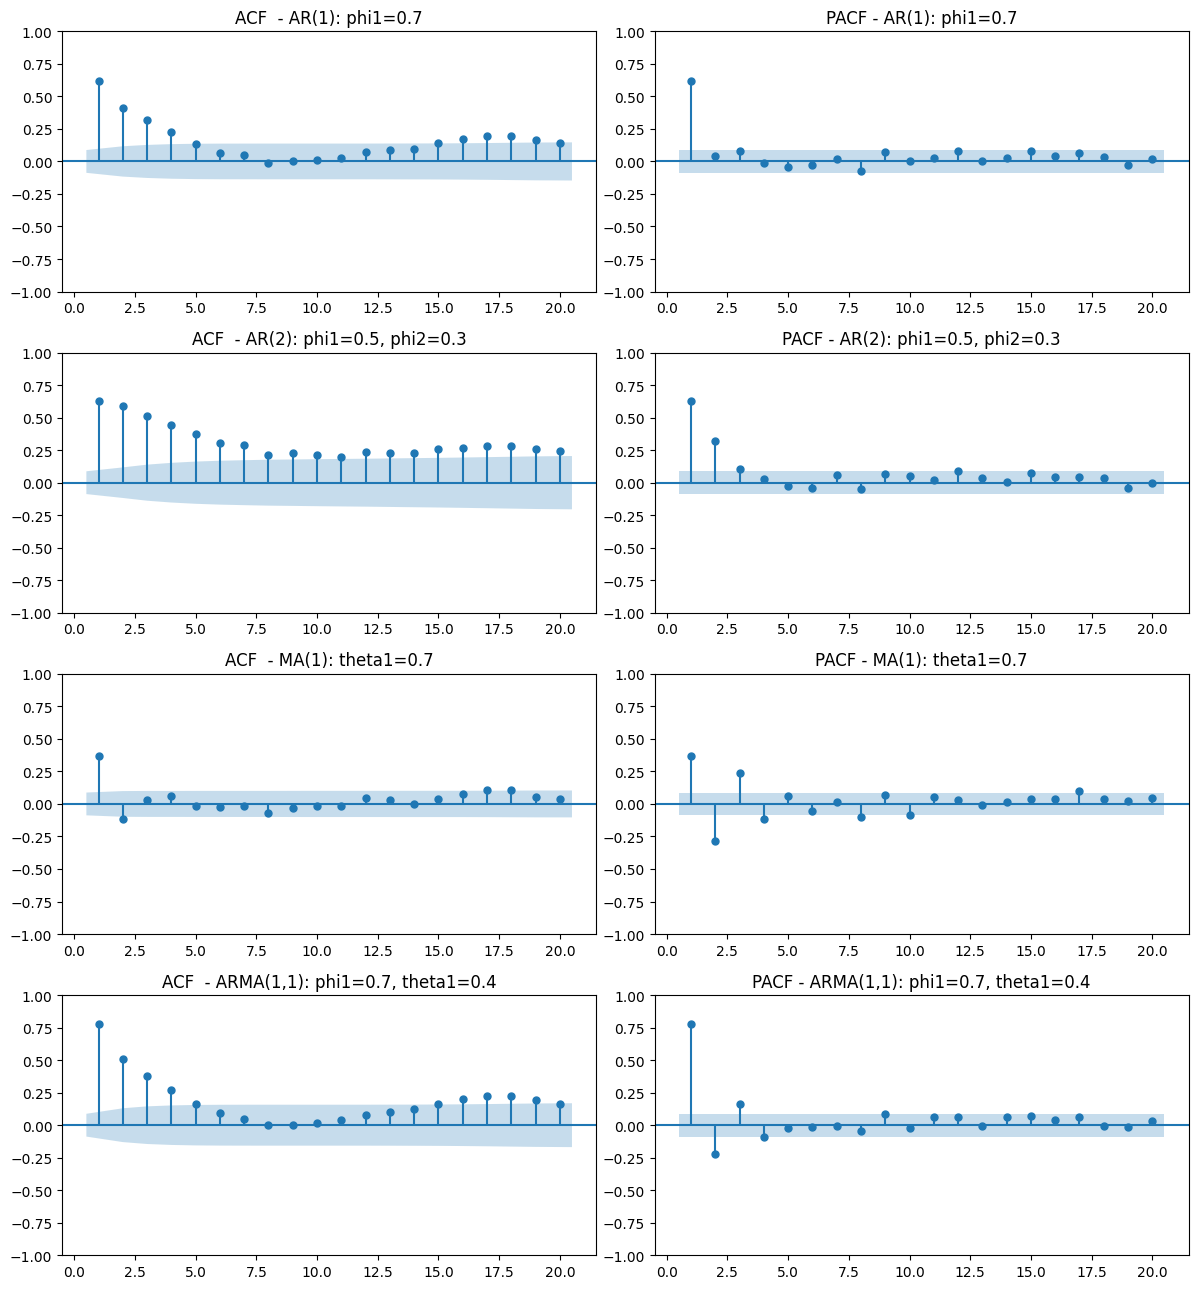

In [ ]:
processes = {
    'AR(1): phi1=0.7':           ArmaProcess(ar=[1, -0.7], ma=[1]),
    'AR(2): phi1=0.5, phi2=0.3': ArmaProcess(ar=[1, -0.5, -0.3], ma=[1]),
    'MA(1): theta1=0.7':         ArmaProcess(ar=[1], ma=[1, 0.7]),        # en el MA el signo NO se invierte
    'ARMA(1,1): phi1=0.7, theta1=0.4': ArmaProcess(ar=[1, -0.7], ma=[1, 0.4]),
}
sim_series = {name: proc.generate_sample(nsample=500, distrvs=np.random.default_rng(1).standard_normal)
              for name, proc in processes.items()}

fig, axes = plt.subplots(4, 2, figsize=(12, 13))
for i, (name, y) in enumerate(sim_series.items()):
    plot_acf(y, lags=20, zero=False, ax=axes[i, 0], title=f'ACF  - {name}')
    plot_pacf(y, lags=20, zero=False, ax=axes[i, 1], title=f'PACF - {name}', method='ywm')
plt.tight_layout()
plt.show()

Con los cuatro procesos simulados se ven las firmas de cada modelo, en el AR(1) la PACF se corta después del rezago 1 y la ACF decae poco a poco, en el AR(2) la PACF se corta después del rezago 2, en el MA(1) es al revés, la ACF se corta después del rezago 1 y la PACF decae alternando signo, y en el ARMA(1,1) las dos decaen poco a poco.

Por eso la regla es que la PACF sugiere p y la ACF sugiere q, aunque con datos reales hay más ruido y esto solo es un punto de partida.

## Ejercicio en clase: la serie misteriosa

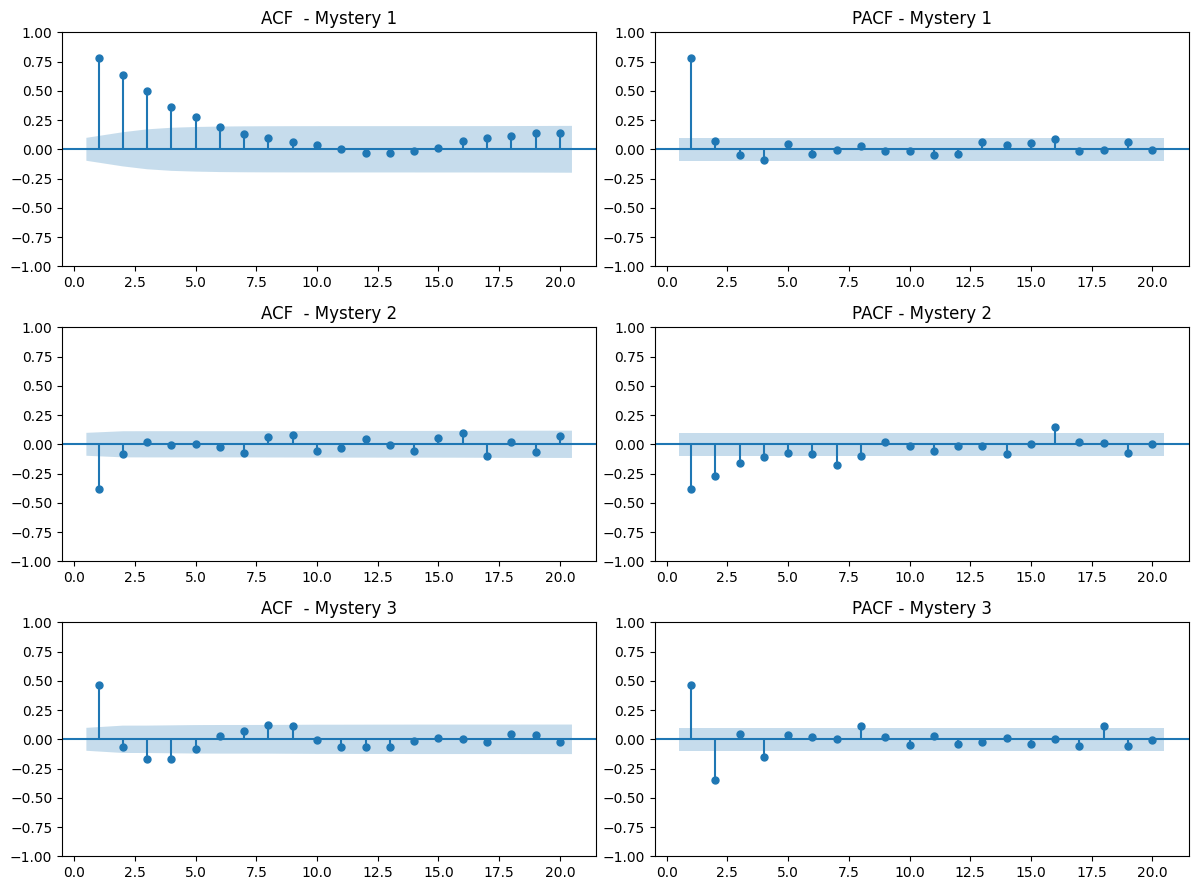

In [ ]:
_secret = [([1, -0.8], [1]), ([1], [1, -0.6]), ([1, -0.6, 0.3], [1])]
mystery = {f'Mystery {k+1}': ArmaProcess(*_secret[k]).generate_sample(400, distrvs=np.random.default_rng(100 + k).standard_normal)
           for k in range(3)}

fig, axes = plt.subplots(3, 2, figsize=(12, 9))
for i, (name, y) in enumerate(mystery.items()):
    plot_acf(y, lags=20, zero=False, ax=axes[i, 0], title=f'ACF  - {name}')
    plot_pacf(y, lags=20, zero=False, ax=axes[i, 1], title=f'PACF - {name}', method='ywm')
plt.tight_layout()
plt.show()

In [ ]:
# Misteriosa 1: la PACF se corta en el rezago 1 y la ACF decae -> propongo un AR(1)
res_m1 = SARIMAX(mystery['Mystery 1'], order=(1, 0, 0), trend='c').fit(disp=False)
print(res_m1.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     -0.0066      0.049     -0.133      0.894      -0.103       0.090
ar.L1          0.7802      0.030     26.397      0.000       0.722       0.838
sigma2         0.9722      0.075     12.976      0.000       0.825       1.119


In [ ]:
# Misteriosa 2: la ACF se corta en el rezago 1 y la PACF decae alternando signo -> propongo un MA(1)
res_m2 = SARIMAX(mystery['Mystery 2'], order=(0, 0, 1), trend='c').fit(disp=False)
print(res_m2.summary().tables[1])

# Misteriosa 3: la PACF se corta en el rezago 2 -> propongo un AR(2)
res_m3 = SARIMAX(mystery['Mystery 3'], order=(2, 0, 0), trend='c').fit(disp=False)
print(res_m3.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     -0.0164      0.016     -0.996      0.319      -0.049       0.016
ma.L1         -0.6765      0.036    -18.613      0.000      -0.748      -0.605
sigma2         1.0135      0.078     12.950      0.000       0.860       1.167
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     -0.0607      0.053     -1.155      0.248      -0.164       0.042
ar.L1          0.6209      0.043     14.561      0.000       0.537       0.704
ar.L2         -0.3496      0.047     -7.437      0.000      -0.442      -0.257
sigma2         1.0396      0.075     13.931      0.000       0.893       1.186


En la misteriosa 1 la PACF tiene un solo pico y la ACF decae poco a poco, por lo que propuse un AR(1), y al estimarlo el coeficiente ar.L1 salió de 0.78 con un p-value de cero, muy cerca del 0.8 verdadero, mientras que la constante no fue significativa.

En la misteriosa 2 la ACF tiene un solo pico negativo y la PACF decae alternando signo, por lo que propuse un MA(1), y en la misteriosa 3 la PACF se corta en el rezago 2, por lo que propuse un AR(2) (los parámetros verdaderos eran theta1 de -0.6 y phi1 de 0.6 con phi2 de -0.3, recordando que ArmaProcess invierte el signo del AR).

Los coeficientes se estiman por máxima verosimilitud, ya que a diferencia de MCO no hay una fórmula cerrada, y en los MA los choques pasados no se observan por lo que el software los tiene que inferir junto con los coeficientes.

## Datos reales: el IGAE de México

In [ ]:
from INEGIpy import Indicadores

# Token de la API del INEGI (se puede pedir uno propio gratis en su página)
TOKEN = 'c4559227-83d3-aeb4-1a8d-bee73f627140'
inegi = Indicadores(TOKEN)

# IGAE mensual: índice base 2018=100, cifras originales (SIN ajuste estacional), total de la economía
# (el INEGI cambió este ID en dic. de 2025)
IGAE_ID = "6207136901"
igaedf = inegi.obtener_df(indicadores=IGAE_ID, nombres="IGAE")

In [ ]:
igaedf.index = pd.to_datetime(igaedf.index)
igaedf.index = igaedf.index.to_period('M').to_timestamp()       # primer día de cada mes
igaedf = igaedf[['IGAE']].apply(pd.to_numeric, errors='coerce')
igaedf = igaedf.sort_index().asfreq('MS')
igaedf['logIGAE'] = np.log(igaedf['IGAE'])
igaedf.tail()

,IGAE,logIGAE
fechas,,
2026-04-01,106.613699,4.669212
2026-05-01,108.549177,4.687203
2026-06-01,107.390831,4.676475
2026-07-01,109.262414,4.693752
2026-08-01,108.317094,4.685063


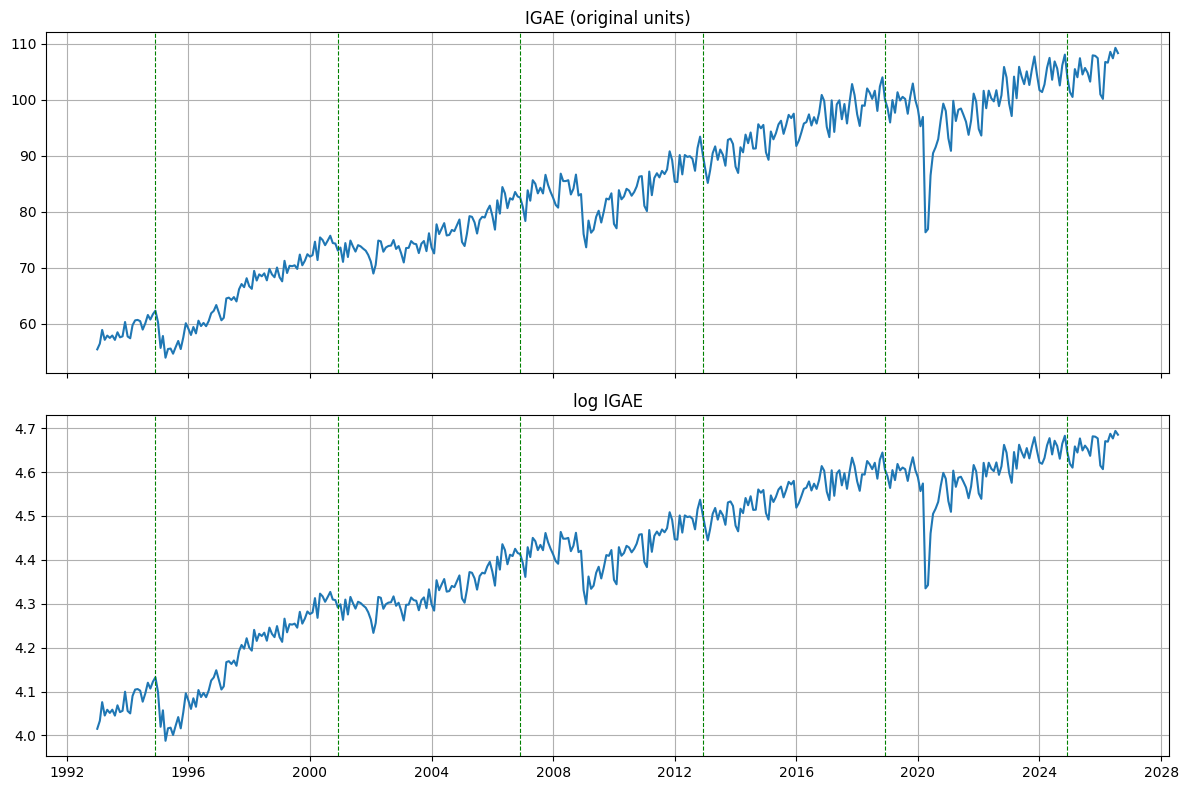

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
axes[0].plot(igaedf.index, igaedf['IGAE'])
axes[0].set_title('IGAE (original units)')
axes[1].plot(igaedf.index, igaedf['logIGAE'])
axes[1].set_title('log IGAE')
for ax in axes:
    for year in [1994, 2000, 2006, 2012, 2018, 2024]:          # inicio de cada sexenio
        ax.axvline(pd.Timestamp(f'{year}-12-01'), color='green', linestyle='--', linewidth=0.8)
    ax.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
annual_log_change = igaedf['logIGAE'].diff(12)
worst_month = annual_log_change.idxmin()
worst_log = float(annual_log_change.min())
worst_simple = float(np.exp(worst_log) - 1)
worst_label = worst_month.strftime('%B %Y')
print(f"Worst annual change: {worst_label}: log difference = {worst_log:.3f}, simple % change = {100*worst_simple:.1f}%")

Worst annual change: May 2020: log difference = -0.276, simple % change = -24.1%


El IGAE es el indicador global de la actividad económica que publica el INEGI cada mes, el cual se parece al PIB pero sale antes, y usamos la serie sin ajuste estacional porque queremos modelar la estacionalidad nosotros.

En la gráfica se ve una tendencia creciente, un patrón estacional muy fuerte y las crisis de 1995, 2009 y 2020, y la gráfica del logaritmo es la correcta para comparar crisis de distintas décadas, ya que en escala logarítmica distancias iguales significan cambios porcentuales iguales.

Como la serie no está desestacionalizada comparamos cada mes con el mismo mes del año anterior, y el peor mes fue mayo de 2020 con una diferencia logarítmica de -0.276, que en realidad es una caída de 24.1% y no de 27.6%, igual que lo que vimos en la Parte A con los cambios grandes.

ADF p-value, log level (ct):     0.2475
ADF p-value, annual growth (c):  0.0011
Annual growth is stationary


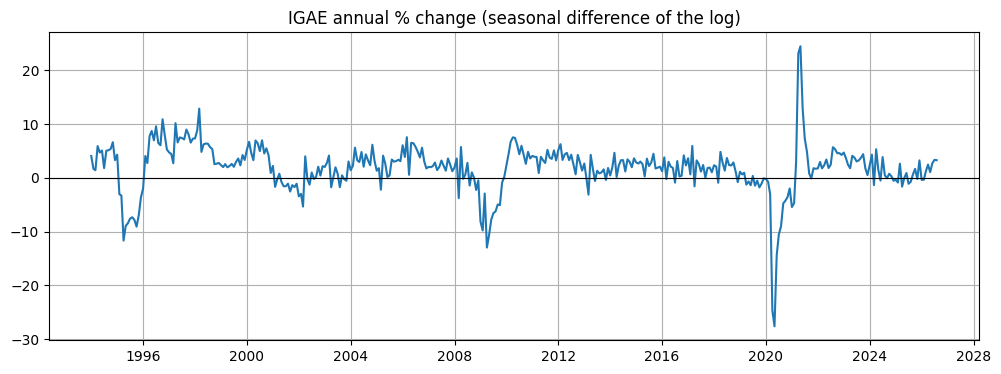

In [ ]:
igaedf['annualgrowth'] = igaedf['logIGAE'].diff(12)

p_adf_level = adf_test(igaedf['logIGAE'], 'ct')['p-value']        # adf_test se definió en la Parte A
p_adf_annual = adf_test(igaedf['annualgrowth'], 'c')['p-value']
igae_stationary = "stationary" if p_adf_annual < 0.05 else "NOT stationary (consider an additional first difference, d=1)"
print(f"ADF p-value, log level (ct):     {p_adf_level:.4f}")
print(f"ADF p-value, annual growth (c):  {p_adf_annual:.4f}")
print(f"Annual growth is {igae_stationary}")

plt.figure(figsize=(12, 4))
plt.plot(igaedf.index, 100 * igaedf['annualgrowth'])
plt.axhline(0, color='black', linewidth=0.8)
plt.title('IGAE annual % change (seasonal difference of the log)')
plt.grid(True)
plt.show()

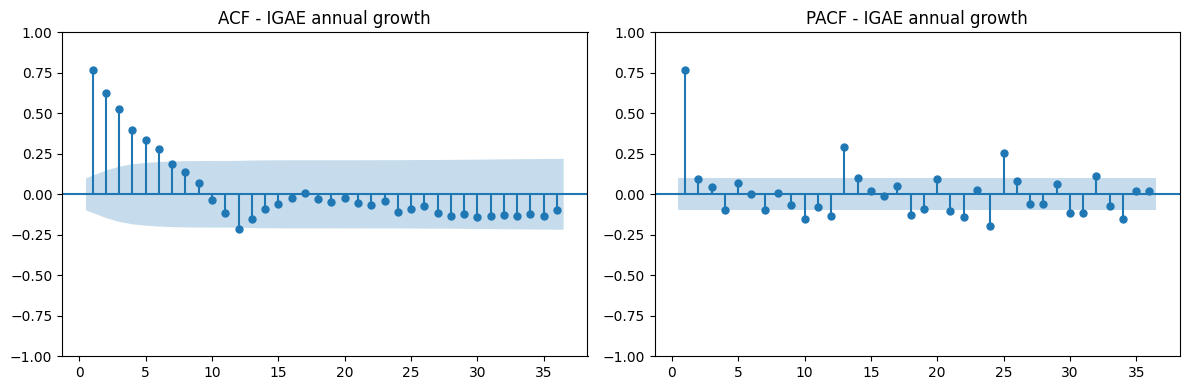

Lag-1 autocorrelation = 0.77 | consecutive significant PACF spikes from lag 1 = 1


In [ ]:
ag = igaedf['annualgrowth'].dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(ag, lags=36, zero=False, ax=axes[0], title='ACF - IGAE annual growth')
plot_pacf(ag, lags=36, zero=False, ax=axes[1], title='PACF - IGAE annual growth', method='ywm')
plt.tight_layout()
plt.show()

acf1 = float(ag.autocorr(1))
pacf_vals, pacf_ci = pacf(ag, nlags=24, alpha=0.05, method='ywm')
signif = (pacf_ci[:, 0] > 0) | (pacf_ci[:, 1] < 0)          # rezagos cuyo intervalo no incluye al cero
# número de rezagos consecutivos significativos de la PACF a partir del rezago 1:
p_suggest = int(np.argmin(signif[1:])) if not signif[1:].all() else 24
print(f"Lag-1 autocorrelation = {acf1:.2f} | consecutive significant PACF spikes from lag 1 = {p_suggest}")

Para encontrar una versión estacionaria del IGAE probamos el nivel en logaritmo, que tuvo un p-value de la ADF de 0.25 por lo que no es estacionario, y el crecimiento anual, que tuvo 0.001 por lo que sí es estacionario.

Esto define los parámetros de diferenciación, ya que modelamos el logaritmo del IGAE con una diferencia estacional y sin primera diferencia, es decir d igual a 0, D igual a 1 y s igual a 12.

En la ACF del crecimiento anual las barras bajan despacio desde 0.77 en el rezago 1, es decir que el crecimiento es muy persistente, y la PACF tiene un pico significativo al principio y luego cae casi a cero, que es la firma de un AR, por lo que empezamos con p igual a 1 y sin términos MA, y dejamos que los diagnósticos digan qué falta.

# Parte D. Construir y evaluar un modelo SARIMA

In [ ]:
igae_log = igaedf['logIGAE'].dropna()
h_test = 24
train = igae_log.iloc[:-h_test]
test = igae_log.iloc[-h_test:]
print(f"Training: {train.index[0]:%Y-%m} to {train.index[-1]:%Y-%m} ({len(train)} months)")
print(f"Test:     {test.index[0]:%Y-%m} to {test.index[-1]:%Y-%m} ({len(test)} months)")
if igae_log.index[-1] != pd.Timestamp('2026-08-01'):
    print("OJO: el último dato no es 2026-08, así que tu periodo de prueba es distinto al de clase")

Training: 1993-01 to 2024-08 (380 months)
Test:     2024-09 to 2026-08 (24 months)


Para evaluar los pronósticos de forma honesta escondemos los últimos 24 meses y solo los usamos al final, y la división tiene que ser cronológica, ya que si la hiciéramos al azar el modelo vería datos del futuro durante el entrenamiento.

In [ ]:
def fit_sarima(y, order, seasonal_order, trend='c', exog=None):
    """Ajusta un modelo SARIMA(X) por máxima verosimilitud."""
    return SARIMAX(y, order=order, seasonal_order=seasonal_order,
                   trend=trend, exog=exog).fit(disp=False)

def diagnose(res, name, plots=True):
    """Tabla de coeficientes, prueba de Ljung-Box sobre los residuales y AIC; gráficas ACF/PACF de los residuales."""
    s = res.model.seasonal_periods or 1
    burn = res.model.k_diff + s * res.model.k_seasonal_diff + 1   # quita los primeros residuales (inicialización)
    resid = res.resid.iloc[burn:]
    m = res.model
    k = m.k_ar_params + m.k_ma_params + m.k_seasonal_ar_params + m.k_seasonal_ma_params   # número de términos ARMA
    lb = acorr_ljungbox(resid, lags=[12, 24], model_df=max(k, 0))
    coefs = pd.DataFrame({'coef': res.params, 'p-value': res.pvalues}).drop('sigma2').round(4)
    print(f"===== {name} =====")
    print(coefs)
    print(f"Ljung-Box p-value (lag 12): {lb['lb_pvalue'].iloc[0]:.4f} | (lag 24): {lb['lb_pvalue'].iloc[1]:.4f}")
    print(f"AIC = {res.aic:.2f}")
    if plots:
        fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
        plot_acf(resid, lags=36, zero=False, ax=axes[0], title=f'Residual ACF - {name}')
        plot_pacf(resid, lags=36, zero=False, ax=axes[1], title=f'Residual PACF - {name}', method='ywm')
        plt.tight_layout()
        plt.show()
    return resid, lb

La prueba de Ljung-Box revisa si un grupo de autocorrelaciones de los residuales son todas cero al mismo tiempo, y su hipótesis nula es que los residuales son ruido blanco, es decir que ya no queda autocorrelación, por lo que aquí queremos un p-value alto (mayor que 0.05), al revés que en la ADF.

Si el p-value es bajo quiere decir que el modelo dejó estructura predecible en los errores y hay que agregarle algo.

===== Model 1: (1,0,0)(0,1,0,12) =====
             coef  p-value
intercept  0.0045   0.0038
ar.L1      0.7677   0.0000
Ljung-Box p-value (lag 12): 0.0000 | (lag 24): 0.0000
AIC = -1536.81


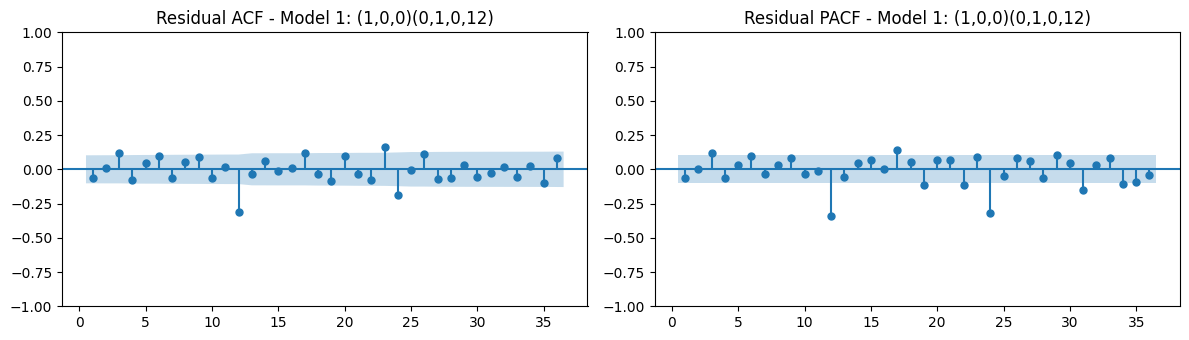

Residual autocorrelation at lag 12 = -0.32


In [ ]:
res1 = fit_sarima(train, (1, 0, 0), (0, 1, 0, 12))
resid1, lb1 = diagnose(res1, 'Model 1: (1,0,0)(0,1,0,12)')
res1_acf12 = float(resid1.autocorr(12))
print(f"Residual autocorrelation at lag 12 = {res1_acf12:.2f}")

En el modelo 1 el coeficiente AR(1) es significativo, pero en los residuales queda un pico negativo de -0.32 en el rezago 12, y un pico negativo en el rezago estacional después de una diferencia estacional es la señal clásica de que falta un término MA estacional (Q igual a 1), ya que significa que la diferencia estacional corrige de más, es decir que parte del choque de hace 12 meses se deshace este año.

===== Model 2: (1,0,0)(0,1,1,12) =====
             coef  p-value
intercept  0.0026      0.0
ar.L1      0.8605      0.0
ma.S.L12  -0.8218      0.0
Ljung-Box p-value (lag 12): 0.0000 | (lag 24): 0.0000
AIC = -1656.18


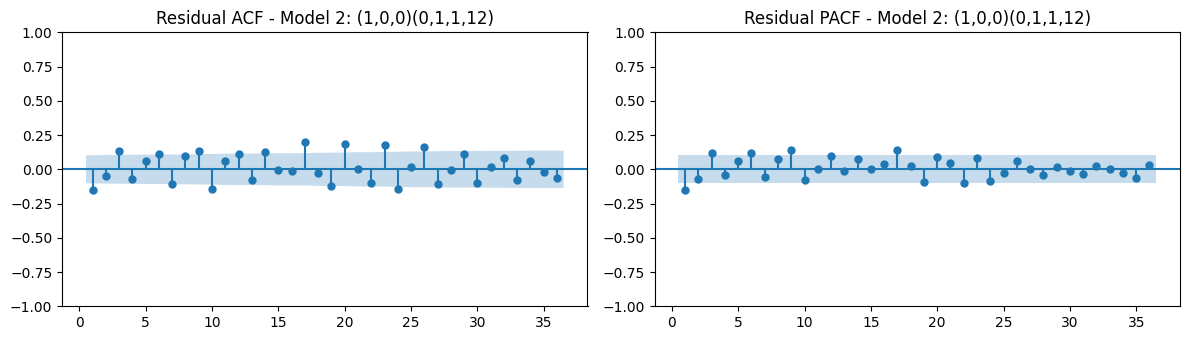

Residual autocorrelation at lag 1 = -0.15


In [ ]:
res2 = fit_sarima(train, (1, 0, 0), (0, 1, 1, 12))
resid2, lb2 = diagnose(res2, 'Model 2: (1,0,0)(0,1,1,12)')
res2_acf1 = float(resid2.autocorr(1))
print(f"Residual autocorrelation at lag 1 = {res2_acf1:.2f}")

Con el MA estacional el pico en el rezago 12 desaparece y el AIC baja de -1536.8 a -1656.2, pero ahora queda un pico de -0.15 en el rezago 1, y como el modelo ya tiene un AR(1) esto sugiere agregar un término MA(1), es decir q igual a 1.

===== Model 3: (1,0,1)(0,1,1,12) =====
             coef  p-value
intercept  0.0014   0.0013
ar.L1      0.9264   0.0000
ma.L1     -0.2638   0.0000
ma.S.L12  -0.8329   0.0000
Ljung-Box p-value (lag 12): 0.0006 | (lag 24): 0.0000
AIC = -1669.05


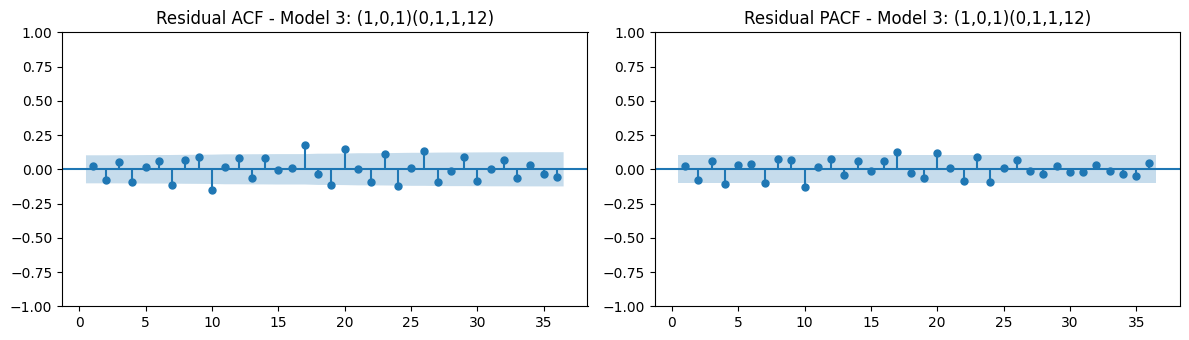

Ljung-Box p-value at lag 24 = 0.0000


In [ ]:
res3 = fit_sarima(train, (1, 0, 1), (0, 1, 1, 12))
resid3, lb3 = diagnose(res3, 'Model 3: (1,0,1)(0,1,1,12)')
lb3_p24 = float(lb3['lb_pvalue'].iloc[1])
print(f"Ljung-Box p-value at lag 24 = {lb3_p24:.4f}")

En el modelo 3 todos los coeficientes son significativos y el AIC baja otra vez a -1669.0, pero algo que no cuadra con el texto del workshop es que la prueba de Ljung-Box dio 0.0006 en el rezago 12 y 0.0000 en el 24, los cuales son menores que 0.05, por lo que con la misma regla del workshop rechazamos que los residuales sean ruido blanco, es decir que todavía queda autocorrelación.

Una posible explicación es que los choques de 2020 fueron tan grandes que ningún modelo de este tipo los puede absorber, pero es algo que vale la pena preguntar en clase.

In [ ]:
from itertools import product

def sarima_grid(y, d, D, s, max_p=2, max_q=2, max_P=1, max_Q=1, trend='c'):
    """Ajusta todas las combinaciones SARIMA(p,d,q)(P,D,Q,s) hasta los órdenes dados; las ordena por AIC."""
    rows = []
    for p, q, P, Q in product(range(max_p + 1), range(max_q + 1), range(max_P + 1), range(max_Q + 1)):
        try:
            res = fit_sarima(y, (p, d, q), (P, D, Q, s), trend=trend)
            burn = d + s * D + 1
            k = p + q + P + Q
            lb_p = acorr_ljungbox(res.resid.iloc[burn:], lags=[2 * s], model_df=k)['lb_pvalue'].iloc[0]
            rows.append({'order': (p, d, q), 'seasonal': (P, D, Q, s), 'AIC': res.aic,
                         'BIC': res.bic, f'Ljung-Box p (lag {2*s})': lb_p, 'n params': k})
        except Exception:
            pass
    return pd.DataFrame(rows).sort_values('AIC').reset_index(drop=True)

grid = sarima_grid(train, d=0, D=1, s=12)     # tarda un par de minutos: son 36 modelos
grid.head(8).round(3)

,order,seasonal,AIC,BIC,Ljung-Box p (lag 24),n params
0,"(1, 0, 1)","(1, 1, 1, 12)",-1670.877,-1647.428,0.0,4
1,"(2, 0, 2)","(1, 1, 1, 12)",-1669.548,-1638.283,0.0,6
2,"(2, 0, 0)","(1, 1, 1, 12)",-1669.253,-1645.805,0.0,4
3,"(1, 0, 1)","(0, 1, 1, 12)",-1669.045,-1649.505,0.0,3
4,"(2, 0, 2)","(0, 1, 1, 12)",-1668.887,-1641.530,0.0,5
5,"(1, 0, 2)","(1, 1, 1, 12)",-1668.707,-1641.350,0.0,5
6,"(2, 0, 1)","(0, 1, 1, 12)",-1666.479,-1643.031,0.0,4
7,"(2, 0, 1)","(1, 1, 1, 12)",-1665.458,-1638.101,0.0,5


In [ ]:
best_order = grid.loc[0, 'order']
best_seasonal = grid.loc[0, 'seasonal']
best_label = f"SARIMA{best_order}{best_seasonal[:3]}_12"
aic_model3 = float(res3.aic)
aic_best = float(grid.loc[0, 'AIC'])
print(f"Best AIC: {best_label} (AIC = {aic_best:.1f}) | Model 3 AIC = {aic_model3:.1f} | difference = {aic_model3 - aic_best:.1f}")

Best AIC: SARIMA(1, 0, 1)(1, 1, 1)_12 (AIC = -1670.9) | Model 3 AIC = -1669.0 | difference = 1.8


El AIC premia el ajuste del modelo pero castiga el número de parámetros, por lo que entre más bajo mejor, y con sarima_grid probamos todas las combinaciones de órdenes pequeños.

El mejor AIC fue el SARIMA(1,0,1)(1,1,1)12 con -1670.9, mientras que nuestro modelo 3 tiene -1669.0, y como la diferencia es de solo 1.8 puntos (menos de 2 a 4) nos quedamos con el modelo 3 por ser más simple.

Lo raro es que en la tabla la columna de Ljung-Box sale 0.0 en todos los modelos, por lo que con la regla del workshop ninguno pasaría la prueba, que es la misma duda del modelo 3.

In [ ]:
c_hat = float(res3.params['intercept'])
phi1_hat = float(res3.params['ar.L1'])
theta1_hat = float(res3.params['ma.L1'])
Theta1_hat = float(res3.params['ma.S.L12'])
mean_growth = c_hat / (1 - phi1_hat)                 # media de largo plazo del crecimiento anual
half_life = np.log(0.5) / np.log(abs(phi1_hat))      # meses
print(f"c = {c_hat:.5f}, phi1 = {phi1_hat:.4f}, theta1 = {theta1_hat:.4f}, Theta1 = {Theta1_hat:.4f}")
print(f"Long-run mean annual growth = {100*mean_growth:.2f}%   |   half-life of a shock to growth = {half_life:.1f} months")

c = 0.00140, phi1 = 0.9264, theta1 = -0.2638, Theta1 = -0.8329
Long-run mean annual growth = 1.90%   |   half-life of a shock to growth = 9.1 months


Si llamamos w al crecimiento anual, es decir el logaritmo del IGAE menos el de hace 12 meses, el modelo 3 dice que w de hoy es una constante, más phi1 por w del mes pasado, más el choque de hoy, más theta1 por el choque del mes pasado, más Theta1 por el choque de hace 12 meses, más theta1 por Theta1 por el choque de hace 13 meses, y este último término aparece porque el MA normal y el estacional se multiplican, por eso se llama modelo estacional multiplicativo.

Phi1 salió de 0.926, es decir que el crecimiento anual es muy persistente y la mitad de un choque al crecimiento desaparece en unos 9.1 meses, por lo que si la economía crece por encima de su promedio este mes lo más probable es que siga así los siguientes meses.

La constante de 0.0014 no es el crecimiento promedio, ya que igual que en el AR(1) de la Parte A la media de largo plazo es la constante entre uno menos phi1, que da 1.9% anual.

Theta1 de -0.264 significa que parte de la sorpresa del mes pasado se revierte este mes, y Theta1 estacional de -0.833, que está cerca de -1, quiere decir que el patrón estacional es muy estable año con año, por lo que la diferencia estacional corrige de más y el modelo deshace casi todo el choque del mismo mes del año pasado.

In [ ]:
def metrics(actual_log, pred_log):
    """RMSE y MAPE calculados en la escala original del IGAE."""
    a, p = np.exp(actual_log), np.exp(pred_log)
    return {'RMSE': float(np.sqrt(np.mean((a - p) ** 2))),
            'MAPE (%)': float(100 * np.mean(np.abs((a - p) / a)))}

# Ingenuo estacional: repite los últimos 12 meses de los datos de entrenamiento
last_year = train.iloc[-12:].values
snaive = pd.Series(np.tile(last_year, int(np.ceil(h_test / 12)))[:h_test], index=test.index)

fc3 = res3.get_forecast(h_test)
res_best = fit_sarima(train, best_order, best_seasonal)
fc_best = res_best.get_forecast(h_test)

eval_table = pd.DataFrame({
    'Seasonal naive': metrics(test, snaive),
    'Model 3 (1,0,1)(0,1,1)': metrics(test, fc3.predicted_mean),
    f'Best AIC {best_label}': metrics(test, fc_best.predicted_mean),
}).T.round(3)
eval_table

,RMSE,MAPE (%)
Seasonal naive,1.813,1.316
"Model 3 (1,0,1)(0,1,1)",3.221,2.743
"Best AIC SARIMA(1, 0, 1)(1, 1, 1)_12",3.731,3.311


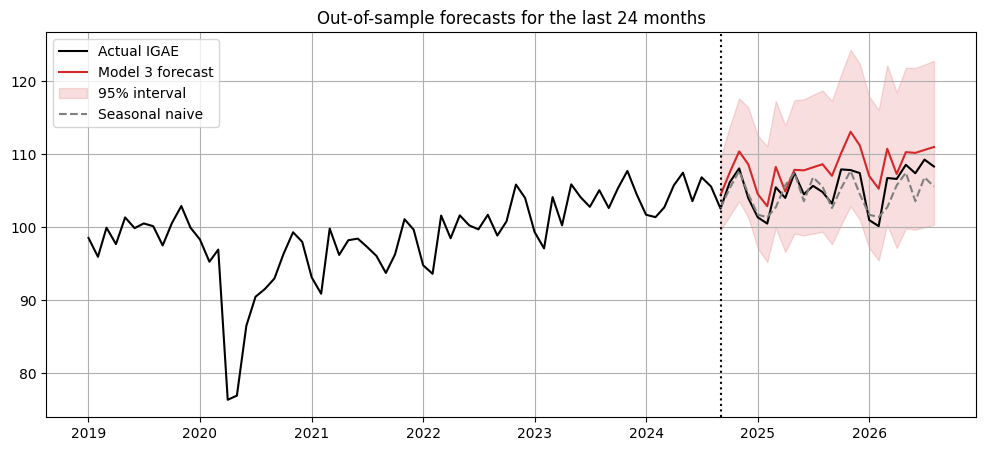

In [ ]:
ci3 = fc3.conf_int(alpha=0.05)
plt.figure(figsize=(12, 5))
plt.plot(np.exp(igae_log['2019-01-01':]), color='black', label='Actual IGAE')
plt.plot(np.exp(fc3.predicted_mean), color='tab:red', label='Model 3 forecast')
plt.fill_between(test.index, np.exp(ci3.iloc[:, 0]), np.exp(ci3.iloc[:, 1]), color='tab:red', alpha=0.15, label='95% interval')
plt.plot(np.exp(snaive), color='tab:grey', linestyle='--', label='Seasonal naive')
plt.axvline(test.index[0], color='black', linestyle=':')
plt.title('Out-of-sample forecasts for the last 24 months')
plt.legend(loc='upper left')
plt.grid(True)
plt.show()

El benchmark ingenuo estacional dice que cada mes va a ser igual al mismo mes del último año observado, y cualquier modelo tiene que ganarle.

El RMSE está en puntos del IGAE y castiga más los errores grandes, y el MAPE es el error promedio como porcentaje del valor real.

En el pronóstico a 24 meses desde un solo origen el ingenuo tuvo un MAPE de 1.32%, el modelo 3 de 2.74% y el de mejor AIC de 3.31%, es decir que el SARIMA no le ganó al benchmark, ya que a 24 meses la persistencia del modelo se pierde y el patrón del último año resultó mejor guía.

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

# SARIMA un paso adelante: mismos coeficientes (estimados con train), aplicados a toda la serie
res3_full = res3.apply(igae_log)
sarima_1step = res3_full.get_prediction(start=test.index[0], end=test.index[-1], dynamic=False).predicted_mean

# Ingenuo estacional un paso adelante
snaive_1step = igae_log.shift(12).loc[test.index]

# Gradient boosting con rezagos del crecimiento anual (versión estacionaria, porque los árboles no extrapolan)
g = igae_log.diff(12)
ml_data = pd.concat({'g': g, **{f'lag{k}': g.shift(k) for k in range(1, 13)}}, axis=1).dropna()
X_train = ml_data.loc[:train.index[-1]].drop(columns='g')
y_train = ml_data.loc[:train.index[-1], 'g']
X_test = ml_data.loc[test.index].drop(columns='g')
gbm = GradientBoostingRegressor(n_estimators=300, max_depth=2, learning_rate=0.05, random_state=0)
gbm.fit(X_train, y_train)

GradientBoostingRegressor(learning_rate=0.05, max_depth=2, n_estimators=300,
                          random_state=0)

In [ ]:
# El modelo predice el crecimiento anual; le sumamos el log de hace 12 meses para regresar al nivel (en log)
gbm_1step = pd.Series(gbm.predict(X_test), index=test.index) + igae_log.shift(12).loc[test.index]

onestep_table = pd.DataFrame({
    'Seasonal naive': metrics(test, snaive_1step),
    'SARIMA Model 3': metrics(test, sarima_1step),
    'Gradient boosting (lags of growth)': metrics(test, gbm_1step),
}).T.round(3)
onestep_table

,RMSE,MAPE (%)
Seasonal naive,1.759,1.262
SARIMA Model 3,1.489,1.130
Gradient boosting (lags of growth),2.207,1.396


En la evaluación un paso adelante cada mes pronosticamos solo el siguiente con la información hasta el mes anterior, y aquí el SARIMA sí ganó con un MAPE de 1.13%, contra 1.26% del ingenuo y 1.40% del gradient boosting.

Al gradient boosting le dimos el crecimiento anual y no el nivel, ya que los modelos de árboles no pueden predecir valores más altos que los que vieron en el entrenamiento.

Esto muestra que un modelo más complejo no es automáticamente mejor, ya que con unos cientos de datos mensuales es difícil ganarle a un SARIMA bien especificado, y los modelos de ML suelen brillar cuando hay muchas series relacionadas o muchas variables externas.

También muestra que el horizonte importa mucho, ya que a un mes el SARIMA aprovecha la persistencia del crecimiento y gana, pero a 24 meses pierde contra el ingenuo.

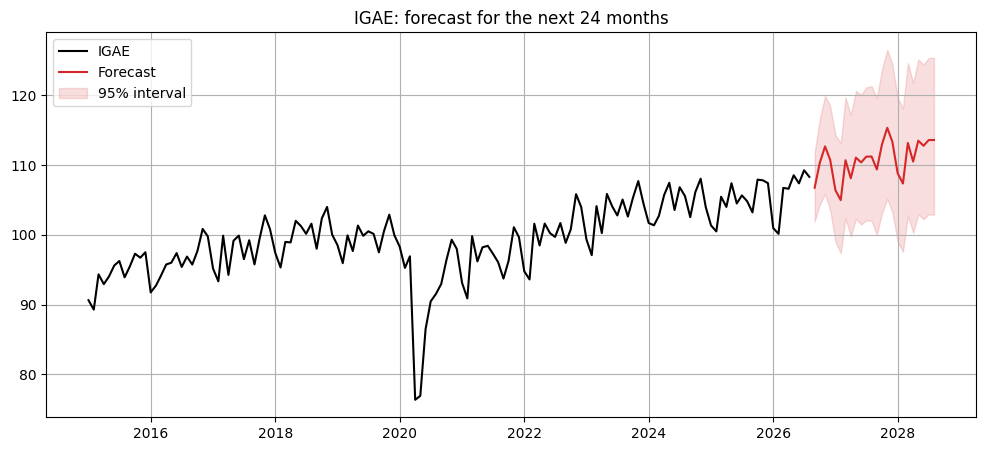

In [ ]:
res_final = fit_sarima(igae_log, (1, 0, 1), (0, 1, 1, 12))
fc_final = res_final.get_forecast(24)
ci_final = fc_final.conf_int(alpha=0.05)

plt.figure(figsize=(12, 5))
plt.plot(np.exp(igae_log['2015-01-01':]), color='black', label='IGAE')
plt.plot(np.exp(fc_final.predicted_mean), color='tab:red', label='Forecast')
plt.fill_between(ci_final.index, np.exp(ci_final.iloc[:, 0]), np.exp(ci_final.iloc[:, 1]), color='tab:red', alpha=0.15, label='95% interval')
plt.title('IGAE: forecast for the next 24 months')
plt.legend(loc='upper left')
plt.grid(True)
plt.show()

Para el pronóstico final volvemos a estimar el modelo con todos los datos y pronosticamos 24 meses, y como modelamos el logaritmo regresamos a la escala original con la exponencial, lo cual da el pronóstico de la mediana del IGAE (la media sería un poco más alta).

El intervalo del 95% se va abriendo conforme crece el horizonte, igual que la gráfica de abanico de la caminata aleatoria del Workshop 3.

## Agregar una variable externa: ARIMAX

In [ ]:
sp500_daily = get_yahoo('^GSPC', start='1990-01-01', end='2026-10-01')

log_sp = np.log(sp500_daily.resample('MS').mean()).asfreq('MS')   # logaritmo del promedio mensual
x_lag1 = log_sp.shift(1).rename('log_sp500_lag1')                   # S&P 500 del mes pasado

x_in = x_lag1.reindex(igae_log.index)
sample = x_in.notna()
y_x = igae_log[sample]
x_x = x_in[sample]

res_x = fit_sarima(y_x, (1, 0, 1), (0, 1, 1, 12), exog=x_x)
res_nox = fit_sarima(y_x, (1, 0, 1), (0, 1, 1, 12))      # misma muestra, sin variable exógena
_ = diagnose(res_x, 'ARIMAX: Model 3 + lagged log S&P 500', plots=False)

===== ARIMAX: Model 3 + lagged log S&P 500 =====
                  coef  p-value
intercept       0.0013   0.0117
log_sp500_lag1  0.1080   0.0000
ar.L1           0.8768   0.0000
ma.L1          -0.2458   0.0000
ma.S.L12       -0.7171   0.0000
Ljung-Box p-value (lag 12): 0.0001 | (lag 24): 0.0000
AIC = -1809.68


In [ ]:
beta_x = float(res_x.params['log_sp500_lag1'])
beta_x_p = float(res_x.pvalues['log_sp500_lag1'])
aic_x, aic_nox = float(res_x.aic), float(res_nox.aic)
print(f"beta = {beta_x:.4f} (p-value = {beta_x_p:.4f}) | AIC with X = {aic_x:.1f} | AIC without X = {aic_nox:.1f}")

beta = 0.1080 (p-value = 0.0000) | AIC with X = -1809.7 | AIC without X = -1795.7


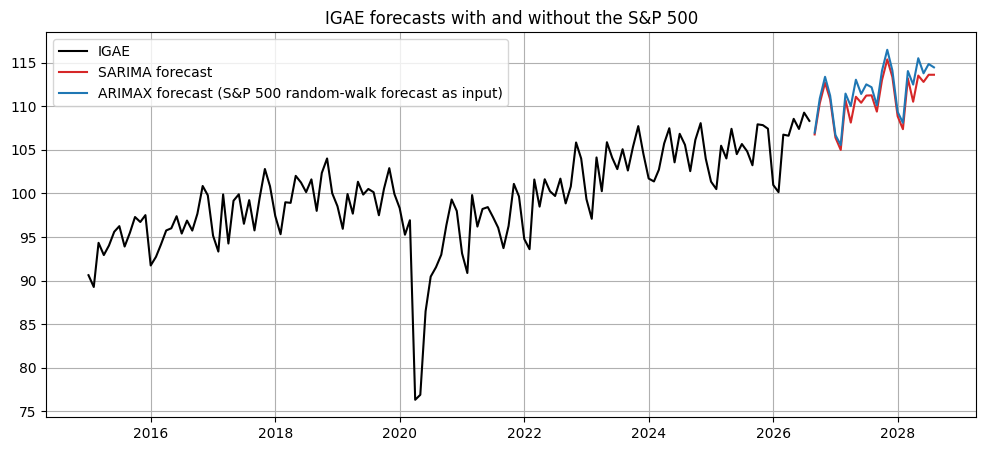

In [ ]:
future_idx = pd.date_range(igae_log.index[-1] + pd.offsets.MonthBegin(1), periods=24, freq='MS')
# meses del S&P 500 que debemos pronosticar (shift(1) necesita que la serie llegue hasta el último mes del pronóstico)
months_needed = len(pd.date_range(log_sp.index[-1] + pd.offsets.MonthBegin(1), future_idx[-1], freq='MS'))

drift_sp = float(log_sp.loc['2000-01-01':].diff().mean())          # deriva (drift) mensual de la caminata aleatoria
sp_future_idx = pd.date_range(log_sp.index[-1] + pd.offsets.MonthBegin(1), periods=max(months_needed, 0), freq='MS')
sp_future = pd.Series(float(log_sp.iloc[-1]) + drift_sp * np.arange(1, len(sp_future_idx) + 1), index=sp_future_idx)
log_sp_ext = pd.concat([log_sp, sp_future])
x_future = log_sp_ext.shift(1).reindex(future_idx).to_frame('log_sp500_lag1')

fc_x = res_x.get_forecast(24, exog=x_future)

plt.figure(figsize=(12, 5))
plt.plot(np.exp(igae_log['2015-01-01':]), color='black', label='IGAE')
plt.plot(np.exp(fc_final.predicted_mean), color='tab:red', label='SARIMA forecast')
plt.plot(np.exp(fc_x.predicted_mean), color='tab:blue', label='ARIMAX forecast (S&P 500 random-walk forecast as input)')
plt.title('IGAE forecasts with and without the S&P 500')
plt.legend(loc='upper left')
plt.grid(True)
plt.show()

La economía de México está muy ligada a la de Estados Unidos y la bolsa es un indicador adelantado, por eso probamos si el S&P 500 del mes pasado ayuda a explicar el IGAE.

SARIMAX estima una regresión con errores SARIMA y la diferencia estacional se aplica a toda la ecuación, por lo que la variable externa se pasa igual que el IGAE, como logaritmo del nivel, y el modelo termina relacionando el crecimiento anual del IGAE con el cambio porcentual anual del S&P 500.

El coeficiente salió de 0.108 con un p-value de cero, es decir que si el cambio anual del S&P 500 del mes pasado es 1 punto porcentual mayor, el crecimiento anual del IGAE de este mes sube alrededor de 0.1 puntos, lo cual es pequeño porque las acciones son mucho más volátiles que la actividad económica, y el AIC mejoró de -1795.7 a -1809.7 en la misma muestra.

El problema es que para pronosticar 24 meses necesitamos los valores futuros del S&P 500, que no conocemos, por lo que también hay que pronosticarlo, aquí con una caminata aleatoria con drift, y el ARIMAX hereda los errores de ese pronóstico.

Por eso una variable externa ayuda más cuando se conoce por adelantado, como los efectos de calendario o las promociones planeadas, o cuando su rezago es por lo menos tan largo como el horizonte del pronóstico.

# Challenge 3 (Partes C y D)

## 3.1 Pronosticar las ventas de la marca 6

### 1. Identificación

Brand 6: 54 months, from 2015-01 to 2019-06


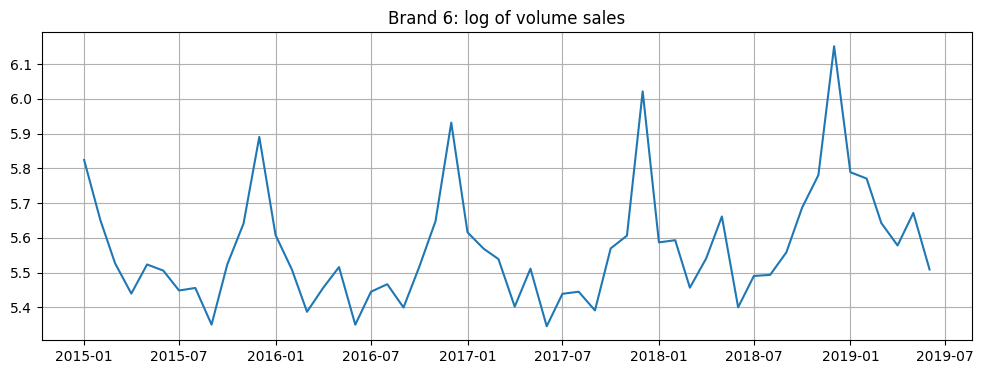

KPSS p-value of the annual % change: 0.010 <= 0.01


,ADF stat,p-value,lags used,obs
log level (ct),-1.2722,0.8946,11.0,42.0
monthly % change (c),-3.1098,0.0258,11.0,41.0
annual % change (c),-3.0307,0.0321,1.0,40.0
annual % change + 1st diff (c),-6.4320,0.0000,2.0,38.0


In [ ]:
y6 = ln_sales['qbrand6tons'].dropna().asfreq('MS')
print(f"Brand 6: {len(y6)} months, from {y6.index[0]:%Y-%m} to {y6.index[-1]:%Y-%m}")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y6.index, y6)
ax.set_title('Brand 6: log of volume sales')
ax.grid(True)
plt.show()

adf6 = pd.DataFrame({
    'log level (ct)': adf_test(y6, 'ct'),
    'monthly % change (c)': adf_test(y6.diff(), 'c'),
    'annual % change (c)': adf_test(y6.diff(12), 'c'),
    'annual % change + 1st diff (c)': adf_test(y6.diff(12).diff(), 'c'),
}).T.round(4)
k6_p, k6_bound = kpss_pvalue(y6.diff(12), 'c')            # función del Challenge 1
print(f"KPSS p-value of the annual % change: {k6_p:.3f} {k6_bound}")
adf6

Stationary series: 42 observations | lags shown: 20


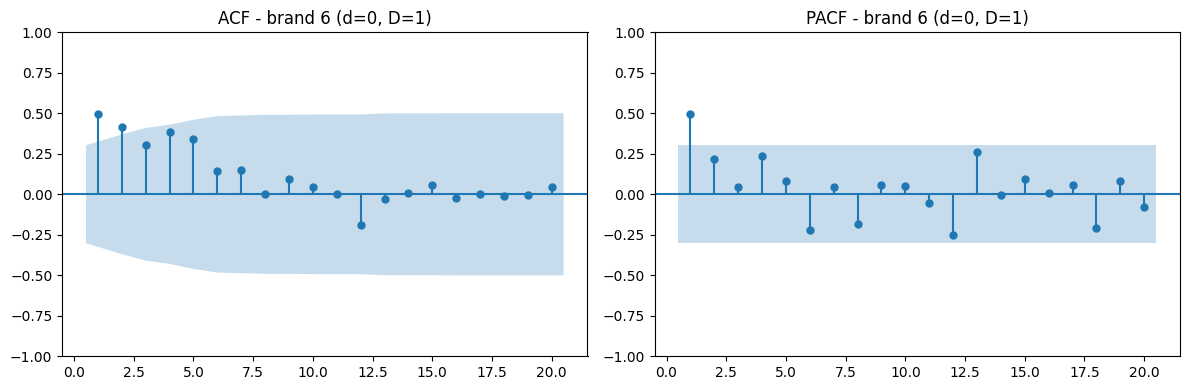

In [ ]:
# DECISIÓN de diferenciación: cambia estos dos valores según el resultado de tus pruebas
d6 = 0
D6 = 1
trend6 = 'n' if (d6 == 1 and D6 == 1) else 'c'      # con d=1 y D=1 el workshop pide trend='n'

# Serie estacionaria que corresponde a esa decisión, para ver su ACF y PACF
w6 = y6.copy()
if D6:
    w6 = w6.diff(12)
if d6:
    w6 = w6.diff()
w6 = w6.dropna()
nl6 = min(24, len(w6) // 2 - 1)                       # la PACF solo se puede calcular hasta la mitad de la muestra
print(f"Stationary series: {len(w6)} observations | lags shown: {nl6}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(w6, lags=nl6, zero=False, ax=axes[0], title=f'ACF - brand 6 (d={d6}, D={D6})')
plot_pacf(w6, lags=nl6, zero=False, ax=axes[1], title=f'PACF - brand 6 (d={d6}, D={D6})', method='ywm')
plt.tight_layout()
plt.show()

Para la marca 6 el nivel en logaritmo tuvo un p-value de la ADF de 0.895, por lo que no rechazamos la raíz unitaria, y el cambio porcentual anual tuvo 0.032 con una KPSS de 0.01 o menos, por lo que las dos pruebas rechazan y es un caso ambiguo.

Por eso decidí usar d igual a 0 y D igual a 1, ya que la diferencia estacional quita la estacionalidad y la ADF del cambio anual ya rechaza la raíz unitaria. Con una diferencia extra la ADF da 0.000, pero creo que la KPSS rechaza porque el crecimiento anual va subiendo de 2016 a 2019 y no porque tenga raíz unitaria, y con tan pocos datos otra diferencia quitaría más observaciones, aunque es una decisión que vale la pena preguntar.

Hay que tomar en cuenta que la base solo tiene 54 meses (de enero de 2015 a junio de 2019), por lo que las pruebas tienen poco poder y la decisión también se apoya en la gráfica.

En la ACF de la serie estacionaria se ve que las primeras barras bajan despacio (de 0.5 en el rezago 1 a 0.34 en el rezago 5) y después entran a la banda, y en la PACF solo hay un pico significativo en el rezago 1 (alrededor de 0.5), por lo que como modelo inicial propongo un AR(1) sin términos MA, es decir un SARIMA(1,0,0)(0,1,0)12, igual que con el IGAE.

### 2. Calibración

In [ ]:
h6 = 12
train6 = y6.iloc[:-h6]
test6 = y6.iloc[-h6:]
print(f"Training: {train6.index[0]:%Y-%m} to {train6.index[-1]:%Y-%m} ({len(train6)} months)")
print(f"Test:     {test6.index[0]:%Y-%m} to {test6.index[-1]:%Y-%m} ({len(test6)} months)")

def diagnose_short(res, name, plots=True):
    """Igual que diagnose de la Parte D, pero ajusta los rezagos al tamaño de la muestra (la base de ventas es corta)."""
    s = res.model.seasonal_periods or 1
    burn = res.model.k_diff + s * res.model.k_seasonal_diff + 1      # quita los residuales de inicialización
    resid = res.resid.iloc[burn:]
    m = res.model
    k = m.k_ar_params + m.k_ma_params + m.k_seasonal_ar_params + m.k_seasonal_ma_params
    lb_lags = [L for L in (6, 12, 24) if k < L < len(resid) - 1]    # solo rezagos que caben en la muestra
    lb = acorr_ljungbox(resid, lags=lb_lags, model_df=k)
    coefs = pd.DataFrame({'coef': res.params, 'p-value': res.pvalues}).drop('sigma2').round(4)
    print(f"===== {name} =====")
    print(coefs)
    for L, p in zip(lb_lags, lb['lb_pvalue']):
        print(f"Ljung-Box p-value (lag {L}): {p:.4f}")
    print(f"AIC = {res.aic:.2f} | residuals used = {len(resid)}")
    if plots:
        nl = max(1, min(24, len(resid) // 2 - 1))
        fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
        plot_acf(resid, lags=nl, zero=False, ax=axes[0], title=f'Residual ACF - {name}')
        plot_pacf(resid, lags=nl, zero=False, ax=axes[1], title=f'Residual PACF - {name}', method='ywm')
        plt.tight_layout()
        plt.show()
    return resid, lb

def model_row(res, name):
    """Una fila de resumen para comparar modelos (sirve como evidencia para la bitácora)."""
    s = res.model.seasonal_periods or 1
    resid = res.resid.iloc[res.model.k_diff + s * res.model.k_seasonal_diff + 1:]
    m = res.model
    k = m.k_ar_params + m.k_ma_params + m.k_seasonal_ar_params + m.k_seasonal_ma_params
    lb12 = acorr_ljungbox(resid, lags=[12], model_df=k)['lb_pvalue'].iloc[0] if k < 12 < len(resid) - 1 else np.nan
    pv = res.pvalues.drop('sigma2')
    return {'model': name, 'AIC': res.aic, 'BIC': res.bic, 'Ljung-Box p (lag 12)': lb12,
            'ARMA terms': k, 'coefs with p > 0.05': ', '.join(pv[pv > 0.05].index) or 'none'}

Training: 2015-01 to 2018-06 (42 months)
Test:     2018-07 to 2019-06 (12 months)


===== Brand 6 - Model 1 (1, 0, 0)(0, 1, 0, 12) =====
             coef  p-value
intercept -0.0033   0.8180
ar.L1      0.3452   0.0437
Ljung-Box p-value (lag 6): 0.6843
Ljung-Box p-value (lag 12): 0.4047
Ljung-Box p-value (lag 24): 0.2791
AIC = -60.58 | residuals used = 29


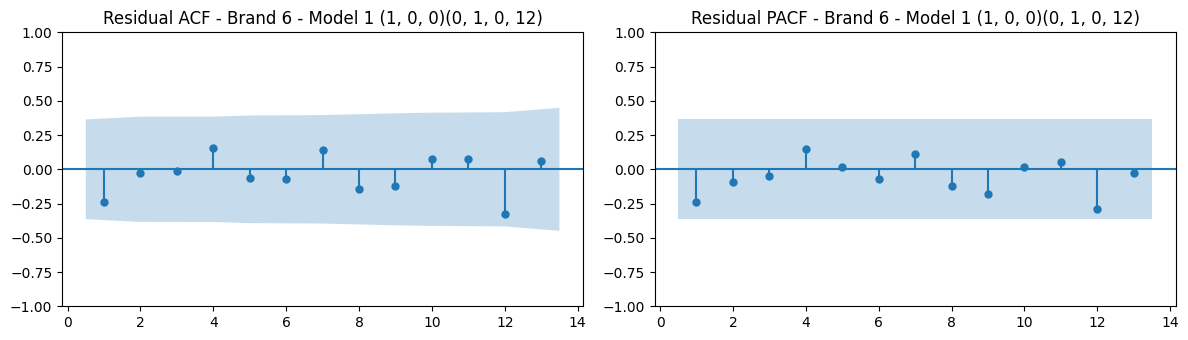

In [ ]:
# Modelo 1 (inicial): AR(1) con la diferenciación elegida. Si tu ACF/PACF sugiere otra cosa, cambia el orden aquí
order6_1, seasonal6_1 = (1, d6, 0), (0, D6, 0, 12)
m6_1 = fit_sarima(train6, order6_1, seasonal6_1, trend=trend6)
_ = diagnose_short(m6_1, f'Brand 6 - Model 1 {order6_1}{seasonal6_1}')

En el modelo 1 el coeficiente ar.L1 salió de 0.345 con un p-value de 0.044, por lo que es significativo, y la prueba de Ljung-Box dio 0.405 en el rezago 12 (0.684 en el rezago 6 y 0.279 en el 24), por lo que no rechazamos que los residuales sean ruido blanco, es decir que este modelo tan simple ya pasa la prueba.

En la ACF de los residuales ninguna barra sale de la banda, aunque hay un pico negativo de -0.32 en el rezago 12, que como vimos con el IGAE puede ser la señal de que falta un MA estacional, por eso en el siguiente modelo agrego un MA estacional para ver si mejora.

===== Brand 6 - Model 2 (1, 0, 0)(0, 1, 1, 12) =====
             coef  p-value
intercept -0.0031   0.7708
ar.L1      0.3437   0.0747
ma.S.L12  -0.4122   0.2735
Ljung-Box p-value (lag 6): 0.4381
Ljung-Box p-value (lag 12): 0.5799
Ljung-Box p-value (lag 24): 0.4536
AIC = -61.55 | residuals used = 29


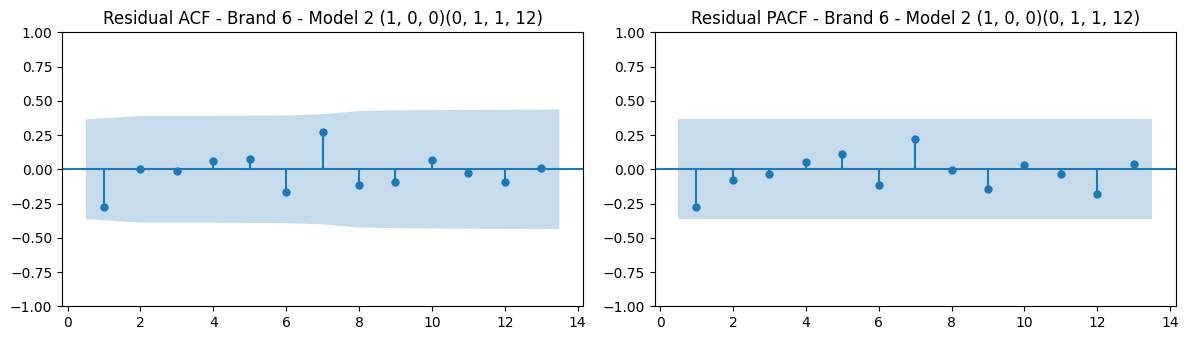

In [ ]:
# Modelo 2: se agrega un MA estacional (Q = 1). Cámbialo si tus residuales del modelo 1 piden otra cosa
order6_2, seasonal6_2 = (1, d6, 0), (0, D6, 1, 12)
m6_2 = fit_sarima(train6, order6_2, seasonal6_2, trend=trend6)
_ = diagnose_short(m6_2, f'Brand 6 - Model 2 {order6_2}{seasonal6_2}')

En el modelo 2 el MA estacional salió de -0.412 con un p-value de 0.274, el AIC pasó de -60.58 a -61.55 y la prueba de Ljung-Box dio 0.580 en el rezago 12, por lo que el término nuevo no es significativo y el AIC mejora menos de 1 punto.

Además el ar.L1 subió su p-value a 0.075 y dejó de ser significativo, por lo que agregar el MA estacional no ayuda y con tan pocos datos solo le quita precisión a los otros coeficientes.

===== Brand 6 - Model 3 (1, 0, 1)(0, 1, 1, 12) =====
             coef  p-value
intercept -0.0010   0.8274
ar.L1      0.9122   0.0000
ma.L1     -0.6135   0.0254
ma.S.L12  -0.4019   0.3493
Ljung-Box p-value (lag 6): 0.1977
Ljung-Box p-value (lag 12): 0.3656
Ljung-Box p-value (lag 24): 0.1434
AIC = -61.33 | residuals used = 29


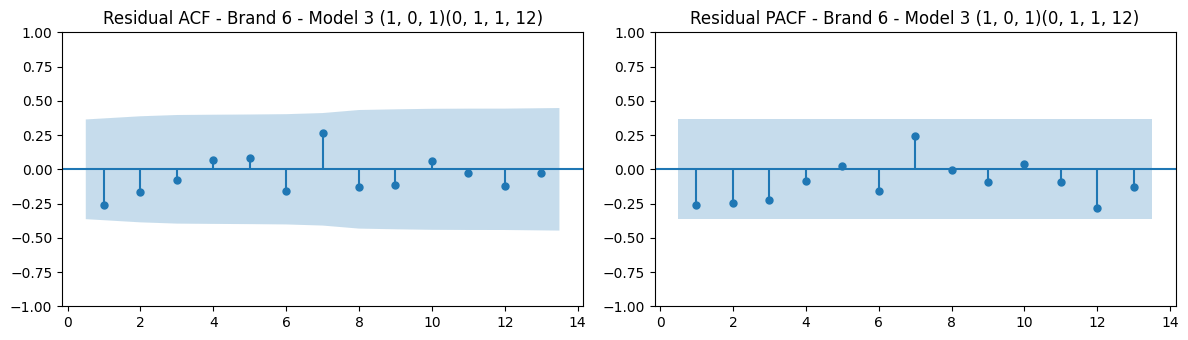

In [ ]:
# Modelo 3: se agrega un MA(1) (q = 1). Cámbialo si tus residuales del modelo 2 piden otra cosa
order6_3, seasonal6_3 = (1, d6, 1), (0, D6, 1, 12)
m6_3 = fit_sarima(train6, order6_3, seasonal6_3, trend=trend6)
_ = diagnose_short(m6_3, f'Brand 6 - Model 3 {order6_3}{seasonal6_3}')

En el modelo 3 el término ma.L1 salió de -0.614 con un p-value de 0.025, por lo que sí es significativo, pero el AIC empeoró de -61.55 a -61.33, el MA estacional sigue sin ser significativo (p = 0.349) y el ar.L1 saltó de 0.34 a 0.91.

Un AR de 0.91 junto con un MA de -0.61 se cancelan en parte, es decir que el modelo está usando dos parámetros para describir casi lo mismo que el AR(1) del modelo 1, lo cual es una señal de que con 42 meses de entrenamiento este modelo ya es demasiado complejo.

In [ ]:
calib6 = pd.DataFrame([model_row(m6_1, f'Model 1 {order6_1}{seasonal6_1[:3]}'),
                       model_row(m6_2, f'Model 2 {order6_2}{seasonal6_2[:3]}'),
                       model_row(m6_3, f'Model 3 {order6_3}{seasonal6_3[:3]}')]).set_index('model').round(3)
calib6

,AIC,BIC,Ljung-Box p (lag 12),ARMA terms,coefs with p > 0.05
model,,,,,
"Model 1 (1, 0, 0)(0, 1, 0)",-60.581,-56.377,0.405,1,intercept
"Model 2 (1, 0, 0)(0, 1, 1)",-61.546,-55.942,0.580,2,"intercept, ar.L1, ma.S.L12"
"Model 3 (1, 0, 1)(0, 1, 1)",-61.326,-54.320,0.366,3,"intercept, ma.S.L12"


In [ ]:
# Búsqueda sistemática por AIC con la misma diferenciación (función de la Parte D)
grid6 = sarima_grid(train6, d=d6, D=D6, s=12, trend=trend6)
print(f"Models that could be fitted: {len(grid6)} of 36")
grid6.head(8).round(3)

Models that could be fitted: 36 of 36


,order,seasonal,AIC,BIC,Ljung-Box p (lag 24),n params
0,"(1, 0, 1)","(1, 1, 0, 12)",-63.107,-56.101,0.149,3
1,"(1, 0, 1)","(1, 1, 1, 12)",-62.813,-54.406,0.109,4
2,"(2, 0, 0)","(1, 1, 0, 12)",-62.427,-55.421,0.150,3
3,"(1, 0, 0)","(1, 1, 0, 12)",-62.350,-56.745,0.420,2
4,"(2, 0, 0)","(1, 1, 1, 12)",-61.879,-53.472,0.097,4
5,"(0, 0, 2)","(1, 1, 0, 12)",-61.664,-54.658,0.202,3
6,"(1, 0, 0)","(0, 1, 1, 12)",-61.546,-55.942,0.454,2
7,"(2, 0, 1)","(1, 1, 1, 12)",-61.506,-51.698,0.112,5


Con sarima_grid el modelo con el AIC más bajo fue el SARIMA(1,0,1)(1,1,0)12 con -63.11, mientras que mis modelos calibrados a mano tuvieron -60.58 (modelo 1), -61.55 (modelo 2) y -61.33 (modelo 3), por lo que la diferencia con el mejor es de 2.5 puntos contra el modelo 1 y de 1.8 contra el modelo 3. El modelo más simple del grid con buen AIC es el SARIMA(1,0,0)(1,1,0)12 con -62.35, que solo tiene dos parámetros y pasa Ljung-Box (0.42 en el rezago 24).

Como la diferencia de AIC contra el mejor del grid es de solo 2.5 puntos, el modelo 1 ya pasa Ljung-Box y su coeficiente AR es significativo, y los modelos 2 y 3 tienen términos que no son significativos, me quedo con el modelo 1, es decir el SARIMA(1,0,0)(0,1,0)12, ya que con 42 meses de entrenamiento prefiero un modelo con un solo parámetro que uno con mejor AIC pero con términos que no puedo sostener.

Con tan pocos datos algunos modelos del grid pueden no converger o dar coeficientes raros, por lo que no tomo el AIC como la única evidencia.

In [ ]:
# Modelo elegido
order6 = order6_1
seasonal6 = seasonal6_1
res6 = fit_sarima(train6, order6, seasonal6, trend=trend6)
_ = diagnose_short(res6, f'Brand 6 - chosen model {order6}{seasonal6}', plots=False)

===== Brand 6 - chosen model (1, 0, 0)(0, 1, 0, 12) =====
             coef  p-value
intercept -0.0033   0.8180
ar.L1      0.3452   0.0437
Ljung-Box p-value (lag 6): 0.6843
Ljung-Box p-value (lag 12): 0.4047
Ljung-Box p-value (lag 24): 0.2791
AIC = -60.58 | residuals used = 29


### 3. Evaluación contra el ingenuo estacional

                             RMSE  MAPE (%)
Seasonal naive             38.978    10.911
SARIMA (1, 0, 0)(0, 1, 0)  39.930    11.106


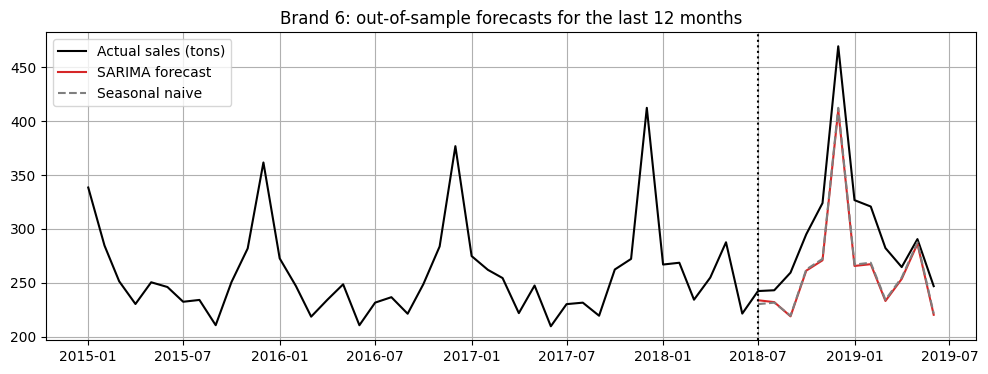

In [ ]:
snaive6 = pd.Series(train6.iloc[-12:].values, index=test6.index)
fc6 = pd.Series(res6.get_forecast(h6).predicted_mean.values, index=test6.index)

# metrics (Parte D) regresa a la escala original con exp, así que aquí el RMSE queda en toneladas
eval6 = pd.DataFrame({
    'Seasonal naive': metrics(test6, snaive6),
    f'SARIMA {order6}{seasonal6[:3]}': metrics(test6, fc6),
}).T.round(3)
print(eval6)

plt.figure(figsize=(12, 4))
plt.plot(np.exp(y6), color='black', label='Actual sales (tons)')
plt.plot(np.exp(fc6), color='tab:red', label='SARIMA forecast')
plt.plot(np.exp(snaive6), color='tab:grey', linestyle='--', label='Seasonal naive')
plt.axvline(test6.index[0], color='black', linestyle=':')
plt.title('Brand 6: out-of-sample forecasts for the last 12 months')
plt.legend(loc='upper left')
plt.grid(True)
plt.show()

En los últimos 12 meses el ingenuo estacional tuvo un RMSE de 38.98 toneladas y un MAPE de 10.91%, y mi modelo tuvo 39.93 y 11.11%, por lo que mi modelo no le gana al benchmark, ya que queda 0.2 puntos de MAPE arriba, es decir que prácticamente empatan.

Esto tiene sentido porque mi modelo es casi el ingenuo estacional con una corrección, ya que con D igual a 1 parte del valor del mismo mes del año pasado y solo le suma el crecimiento anual que espera, y como el AR es de 0.35 esa corrección se desvanece en pocos meses, por lo que a 12 meses los dos pronósticos quedan muy parecidos.

Por eso para este horizonte el modelo no justifica su complejidad contra el ingenuo, aunque sí pasa el diagnóstico, es decir que pasar Ljung-Box no garantiza pronosticar mejor.

Hay que tomar en cuenta que la prueba solo tiene 12 meses, por lo que un mes raro puede cambiar mucho el resultado.

### 4. Pronóstico e interpretación

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.0109      0.011      0.998      0.318      -0.011       0.032
ar.L1          0.5870      0.123      4.774      0.000       0.346       0.828
sigma2         0.0064      0.001      4.280      0.000       0.003       0.009
            forecast (tons)  lower 95%  upper 95%
2019-07-01            261.1      223.3      305.4
2019-08-01            256.7      214.2      307.8
2019-09-01            270.8      224.1      327.2
2019-10-01            305.9      252.5      370.6
2019-11-01            334.5      275.9      405.6
2019-12-01            483.7      398.8      586.7
2020-01-01            336.1      277.1      407.7
2020-02-01            329.7      271.8      400.0
2020-03-01            290.0      239.0      351.8
2020-04-01            271.8      224.0      329.7
2020-05-01            298.4      246.0      362.0
2020-

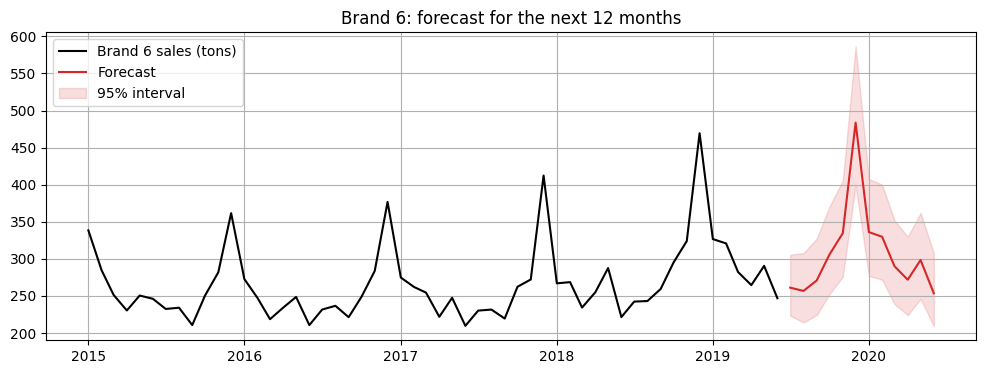

In [ ]:
res6_full = fit_sarima(y6, order6, seasonal6, trend=trend6)
print(res6_full.summary().tables[1])

fc6_full = res6_full.get_forecast(12)
ci6 = fc6_full.conf_int(alpha=0.05)
fc6_table = pd.DataFrame({'forecast (tons)': np.exp(fc6_full.predicted_mean),
                          'lower 95%': np.exp(ci6.iloc[:, 0]),
                          'upper 95%': np.exp(ci6.iloc[:, 1])}).round(1)
print(fc6_table)

plt.figure(figsize=(12, 4))
plt.plot(np.exp(y6), color='black', label='Brand 6 sales (tons)')
plt.plot(fc6_table.index, fc6_table['forecast (tons)'], color='tab:red', label='Forecast')
plt.fill_between(fc6_table.index, fc6_table['lower 95%'], fc6_table['upper 95%'], color='tab:red', alpha=0.15, label='95% interval')
plt.title('Brand 6: forecast for the next 12 months')
plt.legend(loc='upper left')
plt.grid(True)
plt.show()

In [ ]:
p6 = res6_full.params
c6 = float(p6.get('intercept', 0.0))          # constante (0 si el modelo no tiene)
phi6 = float(p6.get('ar.L1', np.nan))         # coeficiente AR(1) (NaN si el modelo no tiene AR)

if d6 == 0 and D6 == 1:
    # la serie modelada es el crecimiento anual, así que su media de largo plazo es c/(1 - phi1) (o c si no hay AR)
    g6 = c6 / (1 - phi6) if not np.isnan(phi6) else c6
    print(f"Long-run mean annual growth of sales = {100*g6:.2f}% (log) = {100*(np.exp(g6)-1):.2f}% (simple)")
else:
    print("With d=1 the modeled series is the change in annual growth, so c/(1-phi1) is no longer the average annual growth")

if not np.isnan(phi6) and abs(phi6) < 1:
    hl6 = np.log(0.5) / np.log(abs(phi6))
    print(f"Half-life of a shock to growth = {hl6:.1f} months")
else:
    print("The model has no AR(1) term (or |phi1| >= 1), so there is no AR half-life to report")

Long-run mean annual growth of sales = 2.65% (log) = 2.69% (simple)
Half-life of a shock to growth = 1.3 months


Al estimar el modelo con todos los datos (54 meses) la constante quedó en 0.0109 con un p-value de 0.318 y el coeficiente ar.L1 en 0.587 con un p-value de 0.000, por lo que el único término significativo es el AR(1).

El phi1 de 0.587 indica qué tan persistente es el crecimiento anual de las ventas, es decir que si este mes las ventas crecen 1 punto más de lo normal contra el mismo mes del año pasado, el siguiente mes se espera que todavía crezcan alrededor de 0.59 puntos más de lo normal.

Este coeficiente subió de 0.345 con los 42 meses de entrenamiento a 0.587 al agregar los últimos 12 meses, lo cual muestra que con tan pocos datos la estimación cambia bastante.

La constante no es el crecimiento promedio, ya que el crecimiento anual de largo plazo que implica el modelo es la constante entre uno menos phi1, que da 2.65% al año (2.69% en cambio porcentual simple), aunque como la constante no es significativa no puedo decir que ese crecimiento sea distinto de cero.

La vida media de un choque al crecimiento es de 1.3 meses, es decir que si las ventas crecen más de lo normal un mes, la mitad de ese efecto desaparece en poco más de un mes y a los 4 meses queda cerca del 12%.

Para los siguientes 12 meses el modelo pronostica ventas de entre 253.5 toneladas (junio de 2020) y 483.7 toneladas (diciembre de 2019), repitiendo el patrón estacional con el pico en diciembre.

Los intervalos del 95% se abren en los primeros tres meses y después se quedan en alrededor de 18% abajo y 21% arriba del pronóstico, ya que el modelo es estacionario en el crecimiento anual y por eso la incertidumbre deja de crecer.

## 3.2 ¿El tipo de cambio ayuda a pronosticar el IGAE?

USD/MXN: 2003-12 to 2026-09 | months without data: 0


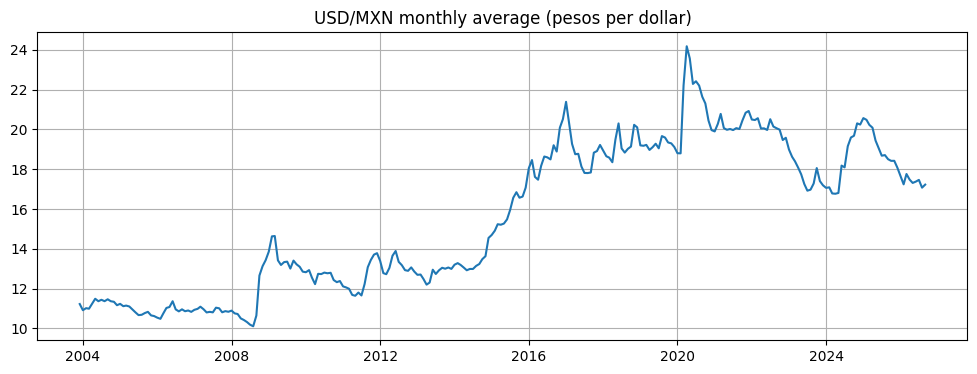

In [ ]:
# end='2026-10-01' porque yfinance no incluye la fecha final, así llegamos hasta el 2026-09-30
mxn_daily = get_yahoo('MXN=X', start='2000-01-01', end='2026-10-01')    # pesos por dólar
log_fx = np.log(mxn_daily.resample('MS').mean()).asfreq('MS')           # logaritmo del promedio mensual
print(f"USD/MXN: {log_fx.first_valid_index():%Y-%m} to {log_fx.index[-1]:%Y-%m} | months without data: {int(log_fx.isna().sum())}")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(np.exp(log_fx))
ax.set_title('USD/MXN monthly average (pesos per dollar)')
ax.grid(True)
plt.show()

In [ ]:
def evaluate_exog(log_x, xname, order=(1, 0, 1), seasonal=(0, 1, 1, 12)):
    """Modelo 3 del IGAE con y sin una variable externa X (log, rezagada un mes).

    1) AIC con y sin X en la MISMA muestra.
    2) RMSE/MAPE en el mismo periodo de prueba de la Parte D (variables train y test):
       - 24 meses adelante: X futura pronosticada con caminata aleatoria con drift estimada SOLO con datos de entrenamiento.
       - un paso adelante: X real del mes anterior (ya se conoce al momento de pronosticar).
    """
    x_in = log_x.shift(1).rename(xname).reindex(igae_log.index)      # X del mes pasado, con las fechas del IGAE
    gaps = x_in[x_in.isna()].index
    first = x_in.first_valid_index()
    # la muestra empieza después del último hueco, para que X no tenga NaN dentro de la muestra
    start = first if (len(gaps) == 0 or gaps.max() < first) else gaps.max() + pd.offsets.MonthBegin(1)
    y_s = igae_log.loc[start:].asfreq('MS')
    x_s = x_in.loc[start:].asfreq('MS')
    end_tr = train.index[-1]                                          # último mes de entrenamiento (Parte D)

    # 1) muestra completa: coeficiente de X y AIC con y sin X
    res_x = fit_sarima(y_s, order, seasonal, exog=x_s)
    res_nox = fit_sarima(y_s, order, seasonal)

    # 2) modelos estimados solo con entrenamiento
    res_x_tr = fit_sarima(y_s.loc[:end_tr], order, seasonal, exog=x_s.loc[:end_tr])
    res_nox_tr = fit_sarima(y_s.loc[:end_tr], order, seasonal)

    # 3) 24 meses adelante: pronóstico de X con caminata aleatoria con drift usando SOLO datos hasta end_tr
    log_x_tr = log_x.loc[:end_tr].dropna()
    if log_x_tr.index[-1] != end_tr:
        print(f"OJO: el último dato de {xname} antes del corte es {log_x_tr.index[-1]:%Y-%m}, no {end_tr:%Y-%m}")
    drift = float(log_x_tr.diff().mean())
    steps = np.arange(1, len(test) + 1)
    x_path = pd.Series(float(log_x_tr.iloc[-1]) + drift * steps, index=test.index)
    x_ext = pd.concat([log_x_tr, x_path])
    prev_month = test.index - pd.DateOffset(months=1)                  # en cada mes de prueba se usa X del mes anterior
    x_test_24 = pd.DataFrame({xname: x_ext.reindex(prev_month).values}, index=test.index)
    fc24_x = pd.Series(res_x_tr.get_forecast(len(test), exog=x_test_24).predicted_mean.values, index=test.index)
    fc24_nox = pd.Series(res_nox_tr.get_forecast(len(test)).predicted_mean.values, index=test.index)

    # 4) un paso adelante: mismos coeficientes de entrenamiento aplicados a toda la serie
    one_x = res_x_tr.apply(y_s, exog=x_s).get_prediction(start=test.index[0], end=test.index[-1], dynamic=False).predicted_mean
    one_nox = res_nox_tr.apply(y_s).get_prediction(start=test.index[0], end=test.index[-1], dynamic=False).predicted_mean
    one_x = pd.Series(np.asarray(one_x), index=test.index)
    one_nox = pd.Series(np.asarray(one_nox), index=test.index)

    t24 = pd.DataFrame({'Seasonal naive': metrics(test, snaive),
                        'SARIMA without X (same sample)': metrics(test, fc24_nox),
                        f'ARIMAX with {xname}': metrics(test, fc24_x)}).T.round(3)
    t1 = pd.DataFrame({'Seasonal naive': metrics(test, snaive_1step),
                       'SARIMA without X (same sample)': metrics(test, one_nox),
                       f'ARIMAX with {xname}': metrics(test, one_x)}).T.round(3)
    return {'res_x': res_x, 'res_nox': res_nox, 'start': start, 'drift': drift, 'x_test_24': x_test_24,
            'fc24_x': fc24_x, 'fc24_nox': fc24_nox, 'one_x': one_x, 'one_nox': one_nox, 't24': t24, 't1': t1}

Esta función hace todo el ejercicio para cualquier variable externa, así lo puedo correr igual para el tipo de cambio y para el S&P 500 y compararlos en las mismas condiciones.

Primero rezaga la variable un mes y la pone en las mismas fechas que el IGAE, luego estima el modelo 3 con y sin la variable en la misma muestra para comparar el AIC, y después lo evalúa en el mismo periodo de prueba de la Parte D.

Para el pronóstico a 24 meses el tipo de cambio futuro se pronostica con una caminata aleatoria con drift calculada solo con datos hasta agosto de 2024, ya que si usara datos posteriores el modelo estaría usando información del futuro, mientras que para el pronóstico de un paso adelante se usa el tipo de cambio real del mes anterior, que ya se conoce al momento de pronosticar.

In [ ]:
fx = evaluate_exog(log_fx, 'log_usdmxn_lag1')
print(f"Common sample starts in {fx['start']:%Y-%m}")
_ = diagnose(fx['res_x'], 'ARIMAX: Model 3 + lagged log USD/MXN', plots=False)

beta_fx = float(fx['res_x'].params['log_usdmxn_lag1'])
beta_fx_p = float(fx['res_x'].pvalues['log_usdmxn_lag1'])
aic_fx, aic_nofx = float(fx['res_x'].aic), float(fx['res_nox'].aic)
print(f"\nbeta = {beta_fx:.4f} (p-value = {beta_fx_p:.4f})")
print(f"AIC with USD/MXN = {aic_fx:.1f} | AIC without = {aic_nofx:.1f} | gain = {aic_nofx - aic_fx:.1f}")

Common sample starts in 2004-01
===== ARIMAX: Model 3 + lagged log USD/MXN =====
                   coef  p-value
intercept        0.0016   0.0077
log_usdmxn_lag1 -0.2297   0.0000
ar.L1            0.9273   0.0000
ma.L1           -0.3613   0.0000
ma.S.L12        -0.9830   0.0000
Ljung-Box p-value (lag 12): 0.0006 | (lag 24): 0.0000
AIC = -1175.24

beta = -0.2297 (p-value = 0.0000)
AIC with USD/MXN = -1175.2 | AIC without = -1152.8 | gain = 22.4


El coeficiente del tipo de cambio salió de -0.230 con un p-value de 0.000, y como el tipo de cambio entra en logaritmo y con la diferencia estacional, es una elasticidad entre tasas de crecimiento, es decir que si el cambio porcentual anual del dólar en pesos del mes pasado es 1 punto mayor, el crecimiento anual del IGAE de este mes baja alrededor de 0.23 puntos.

Una depreciación del peso significa que el USD/MXN sube (se necesitan más pesos por dólar), por lo que según mi modelo una depreciación reduce el crecimiento de la actividad económica, lo cual tiene sentido porque las depreciaciones fuertes del peso suelen llegar junto con crisis, como en 2008 y 2020, cuando el peso se depreció y la actividad cayó al mismo tiempo, por lo que el efecto de que un peso más barato ayude a las exportaciones no alcanza a dominar.

El AIC con el tipo de cambio fue de -1175.2 y sin él de -1152.8 en la misma muestra (desde enero de 2004), por lo que el modelo sí mejora por 22.4 puntos.

24 months ahead (USD/MXN forecast with a random walk with drift estimated on training data only):


,RMSE,MAPE (%)
Seasonal naive,1.813,1.316
SARIMA without X (same sample),1.944,1.583
ARIMAX with log_usdmxn_lag1,2.929,2.439


One step ahead (actual USD/MXN of the previous month):


,RMSE,MAPE (%)
Seasonal naive,1.759,1.262
SARIMA without X (same sample),1.406,1.062
ARIMAX with log_usdmxn_lag1,1.640,1.221


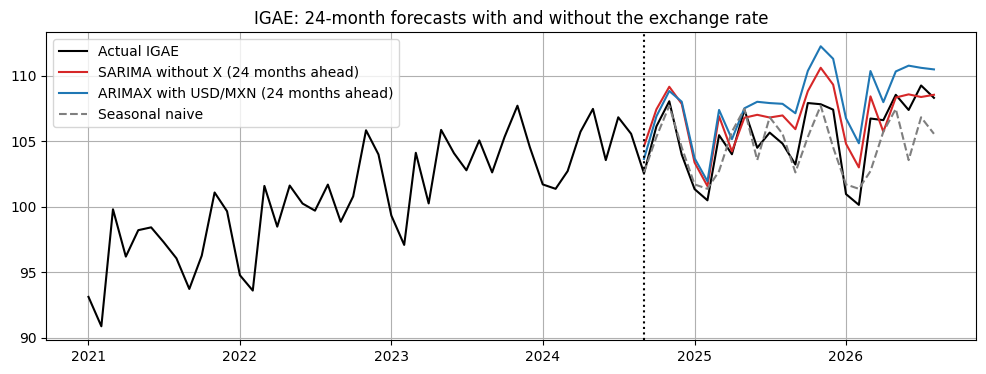

In [ ]:
print("24 months ahead (USD/MXN forecast with a random walk with drift estimated on training data only):")
display(fx['t24'])
print("One step ahead (actual USD/MXN of the previous month):")
display(fx['t1'])

plt.figure(figsize=(12, 4))
plt.plot(np.exp(igae_log['2021-01-01':]), color='black', label='Actual IGAE')
plt.plot(np.exp(fx['fc24_nox']), color='tab:red', label='SARIMA without X (24 months ahead)')
plt.plot(np.exp(fx['fc24_x']), color='tab:blue', label='ARIMAX with USD/MXN (24 months ahead)')
plt.plot(np.exp(snaive), color='tab:grey', linestyle='--', label='Seasonal naive')
plt.axvline(test.index[0], color='black', linestyle=':')
plt.title('IGAE: 24-month forecasts with and without the exchange rate')
plt.legend(loc='upper left')
plt.grid(True)
plt.show()

In [ ]:
# Mismo ejercicio con el S&P 500 de clase, para comparar las dos variables en las mismas condiciones
sp = evaluate_exog(log_sp, 'log_sp500_lag1')

def summary_row(r, xname):
    return {'sample start': f"{r['start']:%Y-%m}",
            'beta': float(r['res_x'].params[xname]),
            'beta p-value': float(r['res_x'].pvalues[xname]),
            'AIC gain (without X - with X)': float(r['res_nox'].aic - r['res_x'].aic),
            'MAPE 24m without X': r['t24'].iloc[1]['MAPE (%)'],
            'MAPE 24m with X': r['t24'].iloc[2]['MAPE (%)'],
            'MAPE 1-step without X': r['t1'].iloc[1]['MAPE (%)'],
            'MAPE 1-step with X': r['t1'].iloc[2]['MAPE (%)']}

compare_x = pd.DataFrame({'USD/MXN': summary_row(fx, 'log_usdmxn_lag1'),
                          'S&P 500': summary_row(sp, 'log_sp500_lag1')}).T
compare_x

,sample start,beta,beta p-value,AIC gain (without X - with X),MAPE 24m without X,MAPE 24m with X,MAPE 1-step without X,MAPE 1-step with X
USD/MXN,2004-01,-0.229746,0.0,22.442652,1.583,2.439,1.062,1.221
S&P 500,1993-01,0.107966,0.000003,13.974813,2.743,4.052,1.13,1.464


Un mes adelante el ARIMAX con el tipo de cambio tuvo un MAPE de 1.22% contra 1.06% del SARIMA sin la variable y 1.26% del ingenuo, por lo que no vale la pena agregarlo, ya que aunque a un mes el tipo de cambio del mes anterior ya se conoce y no hay que pronosticarlo, el modelo sin la variable se equivocó menos.

A 24 meses el ARIMAX tuvo 2.44% contra 1.58% sin la variable y 1.32% del ingenuo, por lo que empeora todavía más, y esto se explica porque a 24 meses hay que pronosticar el tipo de cambio con una caminata aleatoria y el modelo hereda los errores de ese pronóstico, es decir que la ventaja de tener la variable se pierde si no conocemos sus valores futuros.

Comparando las dos variables, el S&P 500 mejoró el AIC en 14.0 puntos y el tipo de cambio en 22.4, y en la prueba ninguna de las dos mejoró el pronóstico, aunque el tipo de cambio empeoró menos (a 24 meses el S&P pasó de 2.74% a 4.05% y el tipo de cambio de 1.58% a 2.44%), por lo que la variable que se ve más útil para el IGAE es el tipo de cambio, pero solo para explicar el pasado y no para pronosticar este periodo.

Hay que tomar en cuenta que las muestras no empiezan en el mismo año (el S&P desde enero de 1993 y el tipo de cambio desde enero de 2004), por eso cada una se compara contra su propio modelo sin variable externa. Algo interesante es que el SARIMA sin variable estimado desde 2004 pronosticó mejor que el modelo 3 estimado desde 1993 (1.06% contra 1.13% a un mes), lo que sugiere que los datos más viejos ya no ayudan tanto.

Creo que la variable mejora el AIC pero no el pronóstico porque la relación viene sobre todo de las crisis, donde el peso y la actividad se mueven juntos y muy fuerte, mientras que en el periodo de prueba (2024 a 2026) no hubo una crisis así y los movimientos del tipo de cambio no se tradujeron en la actividad.

La respuesta puede cambiar con el horizonte, ya que a un mes las dos variables se conocen y lo que importa es qué tanto explican, mientras que a 24 meses importa qué tan bien las podemos pronosticar, y como las dos se pronostican con una caminata aleatoria, a horizontes largos ninguna aporta mucho.

## 3.3 Bitácora de decisiones (Challenge 3.1)

| Decisión | Qué elegí | Evidencia |
|---|---|---|
| Transformación | Logaritmo de las ventas | La varianza crece con el nivel y la diferencia del logaritmo se interpreta como cambio porcentual |
| D (diferencia estacional) | D = 1 | Nivel en log con ADF de 0.895 (no estacionario); cambio anual con ADF de 0.032 (rechaza) y KPSS de 0.01 o menos (también rechaza, caso ambiguo) |
| d (primera diferencia) | d = 0 | La ADF del cambio anual ya rechaza; con una diferencia extra da 0.000, pero la KPSS rechaza por la tendencia del crecimiento 2016-2019 y con 54 meses otra diferencia quita más datos |
| Modelo inicial | SARIMA(1,0,0)(0,1,0)12 | PACF con un solo pico significativo en el rezago 1 (alrededor de 0.5) y ACF que decae en los primeros 5 rezagos |
| Término agregado | MA estacional (Q = 1), modelo 2 | Pico de -0.32 en el rezago 12 de la ACF de los residuales del modelo 1 (dentro de la banda); el término salió de -0.41 con p = 0.27 y el AIC pasó de -60.58 a -61.55, no significativo |
| Término agregado | MA(1) (q = 1), modelo 3 | Coeficiente de -0.61 con p = 0.025, pero el AIC empeoró a -61.33, el MA estacional siguió sin ser significativo (p = 0.35) y el AR saltó a 0.91, por lo que AR y MA se cancelan en parte |
| Comparación con el grid | Mejor AIC: SARIMA(1,0,1)(1,1,0)12 | AIC de -63.11 contra -60.58 del modelo 1 (2.5 puntos) y -61.33 del modelo 3 (1.8 puntos); el más simple con buen AIC es (1,0,0)(1,1,0)12 con -62.35 |
| Modelo final | SARIMA(1,0,0)(0,1,0)12 (modelo 1) | Ljung-Box p = 0.405 en el rezago 12; ar.L1 con p = 0.044 (la constante no es significativa, p = 0.818); AIC a 2.5 puntos del mejor del grid con un solo parámetro; MAPE 11.11% contra 10.91% del ingenuo, es decir que no le gana al benchmark |